# 03 - Embeat Recommendation Model Training

## 1. Mục tiêu

Notebook này trình bày quy trình huấn luyện mô hình gợi ý âm nhạc Embeat
dựa trên phương pháp Content-Based Filtering.

Quy trình bao gồm:

1. Nạp bộ dữ liệu đã được tiền xử lý.
2. Chuẩn hóa 9 đặc trưng âm học bằng StandardScaler.
3. Xây dựng Audio Feature Matrix.
4. Biểu diễn thể loại âm nhạc bằng Multi-Hot Encoding.
5. Xây dựng Genre Matrix dạng Sparse Matrix.
6. Lưu mô hình thành Artifact để phục vụ Recommendation và Backend.

## 2. Phạm vi thực nghiệm

- Dataset: Embeat Spotify Tracks.
- Số lượng dữ liệu thực nghiệm: khoảng 29.985 tracks.
- Audio Features: 9.
- Thuật toán chuẩn hóa: StandardScaler.
- Phương pháp biểu diễn Genre: MultiLabelBinarizer.
- Artifact: embeat_recommender.joblib.

**Lưu ý:** Thực nghiệm hiện tại sử dụng tập dữ liệu 29.985 tracks,
chưa phải phiên bản Full Model với khoảng 18 triệu tracks.

In [3]:
from pathlib import Path
import sys
import json
import pandas as pd

# Đường dẫn dự án trong Google Drive
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/music_recommender_project"
)

# Kiểm tra thư mục dự án
assert PROJECT_ROOT.exists(), "Không tìm thấy thư mục dự án!"
assert (PROJECT_ROOT / "src").exists(), "Không tìm thấy thư mục src!"

# Thêm project root vào Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import module
from src.train import train_model
from src.recommender import EmbeatRecommender

# Cấu hình đường dẫn
INPUT_PATH = (
    PROJECT_ROOT / "data" / "processed" / "balanced_eda.csv"
)

ARTIFACT_PATH = (
    PROJECT_ROOT / "artifacts" / "embeat_recommender.joblib"
)

print("Project root:", PROJECT_ROOT)
print("Input dataset:", INPUT_PATH)
print("Output artifact:", ARTIFACT_PATH)

assert INPUT_PATH.exists(), f"Dataset not found: {INPUT_PATH}"

Project root: /content/drive/MyDrive/music_recommender_project
Input dataset: /content/drive/MyDrive/music_recommender_project/data/processed/balanced_eda.csv
Output artifact: /content/drive/MyDrive/music_recommender_project/artifacts/embeat_recommender.joblib


In [4]:
assert INPUT_PATH.exists(), f"Dataset not found: {INPUT_PATH}"

df = pd.read_csv(INPUT_PATH)

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
display(
    df.isnull().sum().sort_values(ascending=False).head(10)
)

Dataset shape: (30000, 28)

Columns:
['track_id', 'track_name', 'isrc', 'popularity', 'explicit', 'artist_idx', 'artist_id', 'artist_name', 'artist_popularity', 'artist_genres', 'artist_genre_idx', 'album_id', 'album_name', 'release_year', 'duration', 'time_signature', 'tempo', 'key', 'mode', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'source_shard']

First 5 rows:


,track_id,track_name,isrc,popularity,explicit,artist_idx,artist_id,artist_name,artist_popularity,artist_genres,...,mode,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,source_shard
0,7fEoXCZTZFosUFvFQg1BmW,Took Her To The O,USUYG1296663,0.82,1,380,6QtgPSJPSzcnn7dPZ4VINp,King Von,0.79,chicago rap,...,1,0.820,0.592,-7.002,0.2900,0.0149,0.0000,0.1210,0.400,1
1,7fW5TnCdNFhdPw7C2QakEO,Nossas Fotos,BCOOP2500007,0.82,0,819,7cmuxPnXRJxwuYDHfbD8Eu,Zé Felipe,0.75,"arrocha, agronejo, sertanejo universitario, se...",...,1,0.849,0.772,-3.856,0.1230,0.2250,0.0000,0.2490,0.866,1
2,7iL6o9tox1zgHpKUfh9vuC,In Da Club,USIR10300033,0.82,1,123,3q7HBObVc0L8jNeTe5Gofh,50 Cent,0.84,"hip hop, gangster rap, east coast hip hop, rap...",...,0,0.899,0.713,-2.752,0.3660,0.2550,0.0000,0.0708,0.777,1
3,7j74lucZ59vqN67Ipe2ZcY,Maneater,USRC10301821,0.82,0,814,77tT1kLj6mCWtFNqiOmP9H,Daryl Hall & John Oates,0.75,"mellow gold, rock, heartland rock, classic roc...",...,0,0.724,0.498,-13.083,0.0423,0.0405,0.0001,0.0761,0.823,1
4,7m18pBAwjGPROTAf6V2cbw,Don’t Say You Love Me,USA2P2509874,0.82,0,458,5vV3bFXnN6D6N3Nj4xRvaV,Jin,0.78,k-pop,...,1,0.729,0.562,-5.490,0.0304,0.4840,0.0000,0.1050,0.757,1



Missing values:


,0
artist_genres,11322
isrc,3
artist_name,1
album_name,1
popularity,0
track_name,0
artist_idx,0
explicit,0
artist_id,0
artist_popularity,0


In [5]:
model = train_model(
    input_path=INPUT_PATH,
    output_path=ARTIFACT_PATH
)

EMBEAT MODEL TRAINING

[1/5] Loading dataset...
Original shape: (30000, 28)

[2/5] Training audio model...
Cleaned tracks: 29985
Audio matrix: (29985, 9)

[3/5] Building genre matrix...
Genre matrix: (29985, 4211)
Unique genres: 4211

[4/5] Saving model artifact...
Model saved successfully: /content/drive/MyDrive/music_recommender_project/artifacts/embeat_recommender.joblib

[5/5] Generating training metadata...

TRAINING COMPLETED SUCCESSFULLY
{
    "model_name": "EmbeatRecommender",
    "total_tracks": 29985,
    "audio_features": 9,
    "total_genres": 4211,
    "genre_matrix_shape": [
        29985,
        4211
    ],
    "artifact_path": "/content/drive/MyDrive/music_recommender_project/artifacts/embeat_recommender.joblib"
}


In [6]:
assert ARTIFACT_PATH.exists(), "Artifact was not created!"

metadata_path = ARTIFACT_PATH.parent / "training_metadata.json"

assert metadata_path.exists(), "Training metadata was not created!"

with open(metadata_path, "r", encoding="utf-8") as f:
    training_metadata = json.load(f)

print("=== TRAINING METADATA ===")
print(json.dumps(
    training_metadata,
    indent=4,
    ensure_ascii=False
))

print("\nArtifact size (MB):")
print(round(ARTIFACT_PATH.stat().st_size / (1024 ** 2), 2))

=== TRAINING METADATA ===
{
    "model_name": "EmbeatRecommender",
    "total_tracks": 29985,
    "audio_features": 9,
    "total_genres": 4211,
    "genre_matrix_shape": [
        29985,
        4211
    ],
    "artifact_path": "/content/drive/MyDrive/music_recommender_project/artifacts/embeat_recommender.joblib"
}

Artifact size (MB):
5.1


In [7]:
loaded_model = EmbeatRecommender.load_artifact(
    str(ARTIFACT_PATH)
)

print("Loaded tracks:", len(loaded_model.df))
print("Audio matrix:", loaded_model.feature_matrix.shape)
print("Genre matrix:", loaded_model.genre_matrix.shape)

sample_track_id = loaded_model.df.iloc[0]["track_id"]

recommendations = loaded_model.recommend_hybrid(
    track_id=sample_track_id,
    top_k=5
)

print("\n=== SAMPLE RECOMMENDATIONS ===")
display(recommendations)

assert len(recommendations) == 5
assert sample_track_id not in recommendations["track_id"].values

print("\nTRAINING AND ARTIFACT VALIDATION: PASS")

Loaded tracks: 29985
Audio matrix: (29985, 9)
Genre matrix: (29985, 4211)

=== SAMPLE RECOMMENDATIONS ===


,track_id,track_name,artist_name,artist_genres,popularity,audio_similarity,genre_similarity,hybrid_similarity
0,6uFn47ACjqYkc0jADwEdj1,Pop Out (feat. Lil Tjay),Polo G,"rap, chicago rap",0.75,0.911054,0.707107,0.849870
1,2QqJTIlGKRLJC3onkavYEz,Flex (feat. Juice WRLD),Juice WRLD,"rap, melodic rap, chicago rap",0.70,0.930472,0.577350,0.824536
2,1a7WZZZH7LzyvorhpOJFTe,Wasted (feat. Lil Uzi Vert),Juice WRLD,"rap, melodic rap, chicago rap",0.77,0.926040,0.577350,0.821433
3,2WsuSYJNXGKXVYkHPnq2yp,Ransom (with Juice WRLD) - Remix,Juice WRLD,"rap, melodic rap, chicago rap",0.78,0.905475,0.577350,0.807038
4,3JKgcAa7r07ocVWcV8bS0H,21,Polo G,"rap, chicago rap",0.72,0.844245,0.707107,0.803104



TRAINING AND ARTIFACT VALIDATION: PASS


In [8]:
import importlib
import src.recommender as recommender_module

# Nạp lại module từ file Python
importlib.reload(recommender_module)

# Cập nhật class mới
EmbeatRecommender = recommender_module.EmbeatRecommender

# Kiểm tra đường dẫn module đang sử dụng
print("Module path:", recommender_module.__file__)

# Kiểm tra phương thức mới
print(
    "fit_incremental:",
    hasattr(EmbeatRecommender, "fit_incremental")
)

print(
    "finalize_incremental_training:",
    hasattr(EmbeatRecommender, "finalize_incremental_training")
)

assert hasattr(EmbeatRecommender, "fit_incremental")
assert hasattr(EmbeatRecommender, "finalize_incremental_training")

print("\nMODULE RELOAD: PASS")

Module path: /content/drive/MyDrive/music_recommender_project/src/recommender.py
fit_incremental: True
finalize_incremental_training: True

MODULE RELOAD: PASS


In [9]:
import numpy as np
import pandas as pd

from src.recommender import EmbeatRecommender

# Tạo model thử nghiệm
batch_model = EmbeatRecommender()

# Chia dataset thành 3 batch
batches = np.array_split(df, 3)

# Tiếp nhận từng batch
for i, batch in enumerate(batches, start=1):
    batch_model.fit_incremental(batch)

    print(
        f"Batch {i}: {len(batch)} tracks received"
    )

# Kiểm tra dữ liệu đang chờ
assert len(batch_model._pending_batches) == 3

pending_tracks = sum(
    len(batch)
    for batch in batch_model._pending_batches
)

assert pending_tracks == len(df)

print("\nBATCH ACCUMULATION: PASS")

# Hoàn tất huấn luyện
batch_model.finalize_incremental_training()

# Kiểm tra trạng thái sau huấn luyện
assert batch_model.feature_matrix.shape == (
    len(batch_model.df), 9
)

assert len(batch_model.id_to_idx) == len(batch_model.df)

assert len(batch_model._pending_batches) == 0

print("\nBATCH TRAINING: PASS")

Batch 1: 10000 tracks received
Batch 2: 10000 tracks received
Batch 3: 10000 tracks received

BATCH ACCUMULATION: PASS
=== FINALIZING BATCH TRAINING ===
Received batches: 3
Total input tracks: 30000
Cleaned tracks: 29985
Audio matrix: (29985, 9)
BATCH TRAINING COMPLETED

BATCH TRAINING: PASS


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:54: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [10]:
# Model huấn luyện trực tiếp
reference_model = EmbeatRecommender()
reference_model.fit(df)

# So sánh dữ liệu sau làm sạch
pd.testing.assert_frame_equal(
    reference_model.df,
    batch_model.df
)

# So sánh Audio Matrix
np.testing.assert_allclose(
    reference_model.feature_matrix,
    batch_model.feature_matrix
)

# So sánh tham số StandardScaler
np.testing.assert_allclose(
    reference_model.scaler.mean_,
    batch_model.scaler.mean_
)

np.testing.assert_allclose(
    reference_model.scaler.scale_,
    batch_model.scaler.scale_
)

print("DATAFRAME CONSISTENCY: PASS")
print("AUDIO MATRIX CONSISTENCY: PASS")
print("SCALER CONSISTENCY: PASS")

DATAFRAME CONSISTENCY: PASS
AUDIO MATRIX CONSISTENCY: PASS
SCALER CONSISTENCY: PASS


In [11]:
import importlib
import src.train as train_module

importlib.reload(train_module)

print(
    "train_model:",
    hasattr(train_module, "train_model")
)

print(
    "train_model_from_stream:",
    hasattr(train_module, "train_model_from_stream")
)

assert hasattr(train_module, "train_model")
assert hasattr(train_module, "train_model_from_stream")

print("\nTRAINING MODULE VALIDATION: PASS")

train_model: True
train_model_from_stream: True

TRAINING MODULE VALIDATION: PASS


In [12]:
SAMPLE_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "sample_tracks.csv"
)

print("Sample dataset:", SAMPLE_PATH)
print("Exists:", SAMPLE_PATH.exists())

assert SAMPLE_PATH.exists()

Sample dataset: /content/drive/MyDrive/music_recommender_project/data/processed/sample_tracks.csv
Exists: True


In [13]:
import importlib
import src.preprocess as preprocess_module

importlib.reload(preprocess_module)

print(
    "Function available:",
    hasattr(preprocess_module, "validate_and_clean_batch")
)

assert hasattr(
    preprocess_module,
    "validate_and_clean_batch"
)

print("PREPROCESS MODULE: PASS")

Function available: True
PREPROCESS MODULE: PASS


In [14]:
import src.stream_embeat as stream_module
import src.train as train_module

importlib.reload(stream_module)
importlib.reload(train_module)

print("STREAM MODULE: PASS")
print("TRAIN MODULE: PASS")

STREAM MODULE: PASS
TRAIN MODULE: PASS


In [15]:
import os

TEST_ARTIFACT_PATH = (
    PROJECT_ROOT
    / "artifacts"
    / "embeat_stream_test.joblib"
)

os.chdir(PROJECT_ROOT)

stream_model = train_module.train_model_from_stream(
    output_path=TEST_ARTIFACT_PATH,
    hf_token=None,
    sample_ratio=1.0,
    max_total_tracks=5000,
    fallback_to_local=True,
)

assert stream_model.df is not None
assert stream_model.genre_matrix is not None
assert stream_model.feature_matrix.shape[0] == len(stream_model.df)

assert TEST_ARTIFACT_PATH.exists()

print("\nSTREAMING TRAINING INTEGRATION: PASS")

EMBEAT STREAMING BATCH TRAINING

[1/5] Receiving data batches...

[2/5] Finalizing accumulated batches...
=== FINALIZING BATCH TRAINING ===
Received batches: 5
Total input tracks: 4997
Cleaned tracks: 4997
Audio matrix: (4997, 9)
BATCH TRAINING COMPLETED

[3/5] Building genre matrix...
Genre matrix: (4997, 1995)
Unique genres: 1995

[4/5] Saving model artifact...
Model saved successfully: /content/drive/MyDrive/music_recommender_project/artifacts/embeat_stream_test.joblib

[5/5] Generating training metadata...

STREAMING TRAINING COMPLETED
{
    "model_name": "EmbeatRecommender",
    "training_method": "batch_accumulation",
    "total_tracks": 4997,
    "audio_features": 9,
    "total_genres": 1995,
    "audio_matrix_shape": [
        4997,
        9
    ],
    "genre_matrix_shape": [
        4997,
        1995
    ],
    "artifact_path": "/content/drive/MyDrive/music_recommender_project/artifacts/embeat_stream_test.joblib",
    "sample_ratio": 1.0,
    "max_total_tracks": 5000
}

STRE

In [16]:
print("=== STREAM MODEL COLUMNS ===")
print(loaded_stream_model.df.columns.tolist())

print("\nartist_id exists:",
      "artist_id" in loaded_stream_model.df.columns)

print("\nartist_name exists:",
      "artist_name" in loaded_stream_model.df.columns)

print("\nOriginal dataset columns:")
print(df.columns.tolist())

print("\nMissing columns:")
print(
    set(df.columns) -
    set(loaded_stream_model.df.columns)
)

=== STREAM MODEL COLUMNS ===


NameError: name 'loaded_stream_model' is not defined

In [ ]:
result = loaded_stream_model.recommend_hybrid(
    track_id=sample_id,
    top_k=5,
    exclude_same_artist=False
)

display(result)

assert len(result) == 5
assert sample_id not in result["track_id"].values

print("HYBRID RECOMMENDATION: PASS")

In [ ]:
# Kiểm tra trùng ID trong model đã huấn luyện
track_ids = loaded_stream_model.df["track_id"]

duplicate_count = track_ids.duplicated().sum()

print("Total tracks:", len(track_ids))
print("Unique Track IDs:", track_ids.nunique())
print("Duplicate Track IDs:", duplicate_count)

In [ ]:
import inspect
import src.preprocess as preprocess_module

print("========== clean_tracks ==========")
print(inspect.getsource(
    preprocess_module.clean_tracks
))

print("\n========== validate_and_clean_batch ==========")
print(inspect.getsource(
    preprocess_module.validate_and_clean_batch
))

In [ ]:
test_batch = df.iloc[:1000].copy()

clean_batch = preprocess_module.validate_and_clean_batch(
    test_batch
)

print("Original columns:")
print(test_batch.columns.tolist())

print("\nAfter validate_and_clean_batch:")
print(clean_batch.columns.tolist())

print("\nAfter clean_tracks:")
cleaned_again = preprocess_module.clean_tracks(clean_batch)
print(cleaned_again.columns.tolist())

print("\nMissing artist_id:")
print("After batch cleaning:", "artist_id" not in clean_batch.columns)
print("After model cleaning:", "artist_id" not in cleaned_again.columns)

In [ ]:
import inspect

print(inspect.getsource(
    stream_module.train_model_from_stream
))

In [ ]:
from pathlib import Path
import pandas as pd

sample_path = PROJECT_ROOT / "data" / "processed" / "sample_tracks.csv"
original_path = PROJECT_ROOT / "data" / "processed" / "balanced_eda.csv"

sample_columns = pd.read_csv(sample_path, nrows=0).columns.tolist()
original_columns = pd.read_csv(original_path, nrows=0).columns.tolist()

print("=== SAMPLE TRACKS ===")
print("Columns:", sample_columns)
print("Has artist_id:", "artist_id" in sample_columns)

print("\n=== BALANCED EDA ===")
print("Has artist_id:", "artist_id" in original_columns)

print("\n=== MISSING FROM SAMPLE ===")
print(sorted(set(original_columns) - set(sample_columns)))

In [ ]:
import pandas as pd

# Đường dẫn dữ liệu
SOURCE_PATH = PROJECT_ROOT / "data" / "processed" / "balanced_eda.csv"
SAMPLE_PATH = PROJECT_ROOT / "data" / "processed" / "sample_tracks.csv"

# Đọc dữ liệu đã xử lý
source_df = pd.read_csv(SOURCE_PATH)

# Lấy mẫu tối đa 5.000 tracks
sample_df = source_df.sample(
    n=min(5000, len(source_df)),
    random_state=42
).reset_index(drop=True)

# Lưu sample mới
sample_df.to_csv(SAMPLE_PATH, index=False)

print("Sample created successfully!")
print("Source shape:", source_df.shape)
print("Sample shape:", sample_df.shape)
print("Sample columns:", len(sample_df.columns))
print("Has artist_id:", "artist_id" in sample_df.columns)

assert "artist_id" in sample_df.columns
assert len(sample_df) == min(5000, len(source_df))
assert sample_df.columns.tolist() == source_df.columns.tolist()

print("\nSAMPLE DATA VALIDATION: PASS")

In [ ]:
check_df = pd.read_csv(SAMPLE_PATH)

print("Columns:", check_df.columns.tolist())
print("Shape:", check_df.shape)
print("Artist ID available:", "artist_id" in check_df.columns)

print("\nMissing artist_id:", check_df["artist_id"].isna().sum())
print("Unique tracks:", check_df["track_id"].nunique())

assert "artist_id" in check_df.columns
assert check_df["track_id"].is_unique

print("\nSCHEMA VALIDATION: PASS")

In [ ]:
TEST_ARTIFACT_PATH = (
    PROJECT_ROOT
    / "artifacts"
    / "embeat_stream_test.joblib"
)

In [ ]:
import inspect
import importlib
import src.stream_embeat as stream_module

importlib.reload(stream_module)

print("=== STREAM MODULE FUNCTIONS ===")

for name, obj in inspect.getmembers(
    stream_module,
    inspect.isfunction
):
    if obj.__module__ == stream_module.__name__:
        print(f"\n{name}{inspect.signature(obj)}")

In [ ]:
import inspect

print("=== stream_from_local_sample ===")
print(inspect.getsource(stream_module.stream_from_local_sample))

print("\n=== stream_and_train_50pct ===")
print(inspect.getsource(stream_module.stream_and_train_50pct))

In [ ]:
print("=== INCREMENTAL TRAINING METHODS ===")

for name in [
    "fit_incremental",
    "finalize_incremental_training",
    "set_genre_matrix",
    "save_artifact"
]:
    print(
        name,
        hasattr(EmbeatRecommender, name)
    )

In [ ]:
from src.recommender import EmbeatRecommender

# Tạo model thử nghiệm riêng
batch_model = EmbeatRecommender()

# Tiếp nhận từng batch
stream_success = stream_module.stream_from_local_sample(
    sample_csv_path=str(SAMPLE_PATH),
    callback_fn=batch_model.fit_incremental,
    batch_size=1000,
    min_popularity=0
)

assert stream_success is True

print("\nSTREAM RECEIVING: PASS")
print("Pending batches:", len(batch_model._pending_batches))

pending_tracks = sum(
    len(batch)
    for batch in batch_model._pending_batches
)

print("Pending tracks:", pending_tracks)

assert len(batch_model._pending_batches) == 5
assert pending_tracks == 5000

print("BATCH ACCUMULATION: PASS")

In [ ]:
# So sánh dữ liệu sample và model sau huấn luyện
original_ids = set(sample_df["track_id"])
trained_ids = set(batch_model.df["track_id"])

dropped_ids = original_ids - trained_ids

print("Original tracks:", len(sample_df))
print("Trained tracks:", len(batch_model.df))
print("Dropped tracks:", len(dropped_ids))

dropped_df = sample_df[
    sample_df["track_id"].isin(dropped_ids)
].copy()

print("\n=== DROPPED TRACKS ===")
display(dropped_df)

# Kiểm tra nguyên nhân
from src.preprocess import AUDIO_FEATURES

print("\n=== POSSIBLE REASONS ===")

print(
    "Duplicate track IDs:",
    sample_df["track_id"].duplicated().sum()
)

print(
    "Missing audio features:",
    sample_df[AUDIO_FEATURES].isna().any(axis=1).sum()
)

print(
    "Invalid tempo:",
    (pd.to_numeric(
        sample_df["tempo"], errors="coerce"
    ) <= 0).sum()
)

In [ ]:
# Kiểm tra trạng thái model sau huấn luyện
assert batch_model.df is not None
assert batch_model.feature_matrix.shape == (
    len(batch_model.df), 9
)

assert "artist_id" in batch_model.df.columns
assert len(batch_model._pending_batches) == 0

assert batch_model.df["track_id"].is_unique

print("INPUT TRACKS:", 5000)
print("CLEANED TRACKS:", len(batch_model.df))
print("REMOVED TRACKS:", 5000 - len(batch_model.df))

print("AUDIO MATRIX:", batch_model.feature_matrix.shape)
print("METADATA PRESERVATION: PASS")
print("BATCH TRAINING: PASS")

In [ ]:
from sklearn.preprocessing import MultiLabelBinarizer
from scipy.sparse import csr_matrix

genre_lists = (
    batch_model.df["artist_genres"]
    .fillna("")
    .apply(
        lambda x: [
            genre.strip()
            for genre in x.split(",")
            if genre.strip()
        ]
    )
)

mlb = MultiLabelBinarizer(sparse_output=True)

genre_matrix = mlb.fit_transform(genre_lists)

batch_model.set_genre_matrix(genre_matrix)

print("Genre matrix:", batch_model.genre_matrix.shape)
print("Unique genres:", len(mlb.classes_))

assert batch_model.genre_matrix.shape[0] == len(batch_model.df)

print("GENRE MATRIX VALIDATION: PASS")

In [ ]:
print("=== GENRE MATRIX STATUS ===")

print("Genre matrix exists:",
      batch_model.genre_matrix is not None)

if batch_model.genre_matrix is not None:
    print("Genre matrix shape:",
          batch_model.genre_matrix.shape)

    print("Genre matrix type:",
          type(batch_model.genre_matrix))

print("Artist ID preserved:",
      "artist_id" in batch_model.df.columns)

In [ ]:
# Chọn một track làm truy vấn
sample_track_id = batch_model.df.iloc[0]["track_id"]

# 1. Audio-only
audio_result = batch_model.recommend_by_track(
    track_id=sample_track_id,
    top_k=5
)

# 2. Hybrid
hybrid_result = batch_model.recommend_hybrid(
    track_id=sample_track_id,
    top_k=5,
    exclude_same_artist=True
)

# 3. Hybrid + MMR
mmr_result = batch_model.recommend_hybrid_mmr(
    track_id=sample_track_id,
    top_k=5,
    exclude_same_artist=True
)

# Kiểm tra kết quả
assert len(audio_result) == 5
assert len(hybrid_result) == 5
assert len(mmr_result) == 5

# Không đề xuất lại track gốc
assert sample_track_id not in audio_result["track_id"].values
assert sample_track_id not in hybrid_result["track_id"].values
assert sample_track_id not in mmr_result["track_id"].values

# Kiểm tra loại trừ cùng nghệ sĩ
query_artist = batch_model.df.loc[
    batch_model.df["track_id"] == sample_track_id,
    "artist_id"
].iloc[0]

query_artist = str(query_artist)

for result in [hybrid_result, mmr_result]:
    recommended_artists = set(
        result["track_id"].map(
            batch_model.df.set_index("track_id")["artist_id"]
        ).astype(str)
    )

    assert query_artist not in recommended_artists

print("AUDIO-ONLY: PASS")
print("HYBRID: PASS")
print("HYBRID + MMR: PASS")

display(hybrid_result)
display(mmr_result)

In [ ]:
from pathlib import Path

TEST_ARTIFACT_PATH = (
    PROJECT_ROOT
    / "artifacts"
    / "embeat_stream_test.joblib"
)

batch_model.save_artifact(str(TEST_ARTIFACT_PATH))

assert TEST_ARTIFACT_PATH.exists()

print("Artifact saved:", TEST_ARTIFACT_PATH)
print(
    "Artifact size (MB):",
    round(TEST_ARTIFACT_PATH.stat().st_size / (1024 ** 2), 2)
)

print("ARTIFACT SAVE: PASS")

In [ ]:
loaded_stream_model = EmbeatRecommender.load_artifact(
    str(TEST_ARTIFACT_PATH)
)

print("Loaded tracks:", len(loaded_stream_model.df))
print("DataFrame shape:", loaded_stream_model.df.shape)
print("Audio Matrix:", loaded_stream_model.feature_matrix.shape)
print("Genre Matrix:", loaded_stream_model.genre_matrix.shape)

assert len(loaded_stream_model.df) == 4997
assert "artist_id" in loaded_stream_model.df.columns
assert loaded_stream_model.feature_matrix.shape == (4997, 9)
assert loaded_stream_model.genre_matrix.shape == (4997, 1995)

print("ARTIFACT LOAD: PASS")

In [ ]:
import pandas as pd
import numpy as np

# So sánh DataFrame
pd.testing.assert_frame_equal(
    batch_model.df,
    loaded_stream_model.df
)

# So sánh Audio Matrix
np.testing.assert_allclose(
    batch_model.feature_matrix,
    loaded_stream_model.feature_matrix
)

# So sánh Genre Matrix
assert (
    batch_model.genre_matrix != loaded_stream_model.genre_matrix
).nnz == 0

# So sánh kết quả Recommendation
before = batch_model.recommend_hybrid_mmr(
    track_id=sample_track_id,
    top_k=5
)

after = loaded_stream_model.recommend_hybrid_mmr(
    track_id=sample_track_id,
    top_k=5
)

pd.testing.assert_frame_equal(before, after)

print("DATAFRAME CONSISTENCY: PASS")
print("AUDIO MATRIX CONSISTENCY: PASS")
print("GENRE MATRIX CONSISTENCY: PASS")
print("RECOMMENDATION CONSISTENCY: PASS")

In [18]:
import importlib
import src.recommender as recommender_module

importlib.reload(recommender_module)

EmbeatRecommender = recommender_module.EmbeatRecommender

# Sử dụng model đã tải từ artifact
source_df = loaded_stream_model.df.copy()
source_genre_matrix = loaded_stream_model.genre_matrix

assert source_df is not None
assert "artist_id" in source_df.columns

# Tạo dữ liệu thử nghiệm không có artist_id
test_df = source_df.drop(columns=["artist_id"]).copy()

test_model = EmbeatRecommender()
test_model.fit(test_df)

track_id = test_model.df.iloc[0]["track_id"]

# 1. Audio-only không lọc nghệ sĩ
audio_result = test_model.recommend_by_track(
    track_id=track_id,
    top_k=5,
    exclude_same_artist=False
)

assert len(audio_result) == 5
print("AUDIO WITHOUT ARTIST_ID: PASS")

# 2. Audio-only có lọc nghệ sĩ: phải báo lỗi
try:
    test_model.recommend_by_track(
        track_id=track_id,
        top_k=5,
        exclude_same_artist=True
    )
    raise AssertionError("Expected ValueError was not raised.")

except ValueError as e:
    assert "artist_id" in str(e)
    print("ARTIST VALIDATION: PASS")
    print("Error:", e)

# 3. Hybrid với dữ liệu có artist_id
hybrid_model = EmbeatRecommender()
hybrid_model.fit(source_df)
hybrid_model.set_genre_matrix(source_genre_matrix)

hybrid_result = hybrid_model.recommend_hybrid(
    track_id=source_df.iloc[0]["track_id"],
    top_k=5
)

assert len(hybrid_result) == 5
print("HYBRID WITH ARTIST_ID: PASS")

NameError: name 'loaded_stream_model' is not defined

In [19]:

# Lấy dữ liệu từ file sample đã tạo trước đó
sample_df = pd.read_csv(SAMPLE_PATH)

print("Sample shape:", sample_df.shape)

# Chia sample thành 2 batch
batch_1 = sample_df.iloc[:2500].copy()
batch_2 = sample_df.iloc[2500:].copy()

# Tạo model thử nghiệm mới
batch_model = EmbeatRecommender()

# Nhận batch đầu tiên
result_1 = batch_model.fit_incremental(
    batch_1,
    is_first_batch=True
)

# Nhận batch tiếp theo
result_2 = batch_model.fit_incremental(batch_2)

# Kiểm tra tích lũy
assert result_1 is None
assert result_2 is None
assert len(batch_model._pending_batches) == 2

pending_tracks = sum(
    len(batch)
    for batch in batch_model._pending_batches
)

assert pending_tracks == len(sample_df)

print("BATCH ACCUMULATION: PASS")
print("Received batches:", len(batch_model._pending_batches))
print("Pending tracks:", pending_tracks)

# Hoàn tất huấn luyện
batch_model.finalize_incremental_training()

assert batch_model.df is not None
assert batch_model.feature_matrix.shape == (
    len(batch_model.df), 9
)
assert len(batch_model.id_to_idx) == len(batch_model.df)
assert len(batch_model._pending_batches) == 0

print("BATCH TRAINING: PASS")
print("Cleaned tracks:", len(batch_model.df))
print("Audio matrix:", batch_model.feature_matrix.shape)


Sample shape: (5000, 28)
BATCH ACCUMULATION: PASS
Received batches: 2
Pending tracks: 5000
=== FINALIZING BATCH TRAINING ===
Received batches: 2
Total input tracks: 5000
Cleaned tracks: 4997
Audio matrix: (4997, 9)
BATCH TRAINING COMPLETED
BATCH TRAINING: PASS
Cleaned tracks: 4997
Audio matrix: (4997, 9)


In [20]:
import importlib
import src.recommender as recommender_module

importlib.reload(recommender_module)

EmbeatRecommender = recommender_module.EmbeatRecommender

# Tạo model thử nghiệm mới
batch_model = EmbeatRecommender()

# Chia sample thành 2 batch
batch_1 = sample_df.iloc[:2500].copy()
batch_2 = sample_df.iloc[2500:].copy()

# Nhận batch đầu tiên
result_1 = batch_model.fit_incremental(
    batch_1,
    is_first_batch=True
)

# Nhận batch tiếp theo
result_2 = batch_model.fit_incremental(
    batch_2
)

# Kiểm tra tích lũy
assert result_1 is None
assert result_2 is None
assert len(batch_model._pending_batches) == 2

pending_tracks = sum(
    len(batch)
    for batch in batch_model._pending_batches
)

assert pending_tracks == len(sample_df)

print("BATCH ACCUMULATION: PASS")
print("Received batches:", len(batch_model._pending_batches))
print("Pending tracks:", pending_tracks)

# Hoàn tất huấn luyện
batch_model.finalize_incremental_training()

# Kiểm tra model sau huấn luyện
assert batch_model.df is not None
assert batch_model.feature_matrix.shape == (
    len(batch_model.df), 9
)
assert len(batch_model.id_to_idx) == len(batch_model.df)
assert len(batch_model._pending_batches) == 0

print("BATCH TRAINING: PASS")
print("Cleaned tracks:", len(batch_model.df))
print("Audio matrix:", batch_model.feature_matrix.shape)


BATCH ACCUMULATION: PASS
Received batches: 2
Pending tracks: 5000
=== FINALIZING BATCH TRAINING ===
Received batches: 2
Total input tracks: 5000
Cleaned tracks: 4997
Audio matrix: (4997, 9)
BATCH TRAINING COMPLETED
BATCH TRAINING: PASS
Cleaned tracks: 4997
Audio matrix: (4997, 9)


In [21]:

# Model huấn luyện trực tiếp
reference_model = EmbeatRecommender()
reference_model.fit(sample_df)

# So sánh DataFrame
pd.testing.assert_frame_equal(
    reference_model.df,
    batch_model.df
)

# So sánh Audio Matrix
np.testing.assert_allclose(
    reference_model.feature_matrix,
    batch_model.feature_matrix
)

# So sánh StandardScaler
np.testing.assert_allclose(
    reference_model.scaler.mean_,
    batch_model.scaler.mean_
)

np.testing.assert_allclose(
    reference_model.scaler.scale_,
    batch_model.scaler.scale_
)

print("DATAFRAME CONSISTENCY: PASS")
print("AUDIO MATRIX CONSISTENCY: PASS")
print("SCALER CONSISTENCY: PASS")


DATAFRAME CONSISTENCY: PASS
AUDIO MATRIX CONSISTENCY: PASS
SCALER CONSISTENCY: PASS


In [22]:

from sklearn.preprocessing import MultiLabelBinarizer
from pathlib import Path
import scipy.sparse as sp
import pandas as pd
import numpy as np

# Tạo Genre Matrix từ dữ liệu đã làm sạch
genre_lists = (
    batch_model.df["artist_genres"]
    .fillna("")
    .apply(
        lambda x: [
            genre.strip()
            for genre in str(x).split(",")
            if genre.strip()
        ]
    )
)

mlb = MultiLabelBinarizer(sparse_output=True)
genre_matrix = mlb.fit_transform(genre_lists)

batch_model.set_genre_matrix(genre_matrix)

print("Genre matrix:", batch_model.genre_matrix.shape)
print("Unique genres:", len(mlb.classes_))

assert batch_model.genre_matrix.shape[0] == len(batch_model.df)

print("GENRE MATRIX: PASS")


Genre matrix: (4997, 1995)
Unique genres: 1995
GENRE MATRIX: PASS


In [23]:

TEST_ARTIFACT_PATH = (
    PROJECT_ROOT
    / "artifacts"
    / "embeat_batch_test.joblib"
)

# Lưu model
batch_model.save_artifact(str(TEST_ARTIFACT_PATH))

assert TEST_ARTIFACT_PATH.exists()

print("Artifact saved:", TEST_ARTIFACT_PATH)
print(
    "Artifact size (MB):",
    round(TEST_ARTIFACT_PATH.stat().st_size / (1024 ** 2), 2)
)

# Tải lại model
loaded_model = EmbeatRecommender.load_artifact(
    str(TEST_ARTIFACT_PATH)
)

print("\nLoaded tracks:", len(loaded_model.df))
print("Audio matrix:", loaded_model.feature_matrix.shape)
print("Genre matrix:", loaded_model.genre_matrix.shape)

assert len(loaded_model.df) == len(batch_model.df)
assert loaded_model.feature_matrix.shape == batch_model.feature_matrix.shape
assert loaded_model.genre_matrix.shape == batch_model.genre_matrix.shape

print("ARTIFACT LOAD: PASS")


Model saved successfully: /content/drive/MyDrive/music_recommender_project/artifacts/embeat_batch_test.joblib
Artifact saved: /content/drive/MyDrive/music_recommender_project/artifacts/embeat_batch_test.joblib
Artifact size (MB): 0.96

Loaded tracks: 4997
Audio matrix: (4997, 9)
Genre matrix: (4997, 1995)
ARTIFACT LOAD: PASS


In [24]:

# 1. DataFrame
pd.testing.assert_frame_equal(
    batch_model.df,
    loaded_model.df
)

# 2. Audio Matrix
np.testing.assert_allclose(
    batch_model.feature_matrix,
    loaded_model.feature_matrix
)

# 3. Genre Matrix
genre_diff = (
    batch_model.genre_matrix != loaded_model.genre_matrix
).nnz

assert genre_diff == 0

# 4. StandardScaler
np.testing.assert_allclose(
    batch_model.scaler.mean_,
    loaded_model.scaler.mean_
)

np.testing.assert_allclose(
    batch_model.scaler.scale_,
    loaded_model.scaler.scale_
)

print("DATAFRAME CONSISTENCY: PASS")
print("AUDIO MATRIX CONSISTENCY: PASS")
print("GENRE MATRIX CONSISTENCY: PASS")
print("SCALER CONSISTENCY: PASS")


DATAFRAME CONSISTENCY: PASS
AUDIO MATRIX CONSISTENCY: PASS
GENRE MATRIX CONSISTENCY: PASS
SCALER CONSISTENCY: PASS


In [25]:

sample_track_id = batch_model.df.iloc[0]["track_id"]

before = batch_model.recommend_hybrid_mmr(
    track_id=sample_track_id,
    top_k=5
)

after = loaded_model.recommend_hybrid_mmr(
    track_id=sample_track_id,
    top_k=5
)

pd.testing.assert_frame_equal(before, after)

print("RECOMMENDATION CONSISTENCY: PASS")
display(after)


RECOMMENDATION CONSISTENCY: PASS


,track_id,track_name,artist_name,artist_genres,popularity,audio_similarity,genre_similarity,hybrid_similarity,mmr_score
0,7uL1ZsdxI8l4sgEsgCmTlG,Entre Beso Y Beso,La Arrolladora Banda El Limón De Rene Camacho,"norteno, banda, musica mexicana",0.73,0.889494,1.000000,0.922646,0.645852
1,6cJzRkCxgWikIKAsJCkoQL,Actos De Un Tonto,Conjunto Primavera,"banda, norteno, musica mexicana, musica chihua...",0.71,0.853365,0.866025,0.857163,0.355413
2,0sfs8U4743dBlUKKxN7pye,Mi Olvido,Banda MS de Sergio Lizárraga,"norteno, banda, musica mexicana",0.71,0.830812,1.000000,0.881568,0.333690
3,1tzj4DDVNp6X2ltpdTGtZW,La Suma,Javier Rosas Y Su Artillería Pesada,"norteno, musica mexicana, banda, corrido",0.70,0.814434,0.866025,0.829912,0.327149
4,4lac6b0JIjh4hQiW9IGKea,Quién Es Usted,"Sergio Vega ""El Shaka""","norteno, musica mexicana, musica sonorense, banda",0.74,0.687018,0.866025,0.740720,0.319295


In [26]:

from pathlib import Path

ARTIFACT_DIR = PROJECT_ROOT / "artifacts"

print("=== ARTIFACT DIRECTORY ===")

for path in sorted(ARTIFACT_DIR.glob("*.joblib")):
    print(
        path.name,
        "|",
        round(path.stat().st_size / (1024 ** 2), 2),
        "MB"
    )

print("\n=== MAIN ARTIFACT ===")

MAIN_ARTIFACT = ARTIFACT_DIR / "embeat_recommender.joblib"

print("Exists:", MAIN_ARTIFACT.exists())
print("Path:", MAIN_ARTIFACT)

assert MAIN_ARTIFACT.exists(), (
    "Main model artifact does not exist!"
)

print("\nARTIFACT PATH VALIDATION: PASS")


=== ARTIFACT DIRECTORY ===
embeat_batch_test.joblib | 0.96 MB
embeat_recommender.joblib | 5.1 MB
embeat_stream_test.joblib | 0.96 MB

=== MAIN ARTIFACT ===
Exists: True
Path: /content/drive/MyDrive/music_recommender_project/artifacts/embeat_recommender.joblib

ARTIFACT PATH VALIDATION: PASS


In [27]:

# Tải artifact chính, không ghi đè hay sửa file
main_model = EmbeatRecommender.load_artifact(
    str(MAIN_ARTIFACT)
)

print("=== MAIN MODEL VALIDATION ===")
print("Tracks:", len(main_model.df))
print("Audio matrix:", main_model.feature_matrix.shape)
print("Genre matrix:", main_model.genre_matrix.shape)
print("Unique Track IDs:", main_model.df["track_id"].nunique())

assert len(main_model.df) == 29985
assert main_model.feature_matrix.shape == (29985, 9)
assert main_model.genre_matrix.shape[0] == 29985
assert main_model.df["track_id"].is_unique

print("\nMAIN MODEL LOAD: PASS")


=== MAIN MODEL VALIDATION ===
Tracks: 29985
Audio matrix: (29985, 9)
Genre matrix: (29985, 4211)
Unique Track IDs: 29985

MAIN MODEL LOAD: PASS


In [28]:

import inspect

methods_to_check = [
    "recommend_by_track",
    "recommend_hybrid",
    "recommend_hybrid_mmr",
    "recommend_by_taste_profile",
    "recommend_by_popularity",
    "search_tracks",
    "get_track_details",
]

print("=== BACKEND METHOD CONTRACT ===")

for method_name in methods_to_check:
    method = getattr(main_model, method_name, None)

    if method is None:
        print(method_name, ": MISSING")
    else:
        print(method_name, inspect.signature(method))

print("\n=== REQUIRED COLUMNS ===")

for col in [
    "track_id",
    "track_name",
    "artist_id",
    "artist_name",
    "artist_genres",
    "popularity",
]:
    print(f"{col}: {col in main_model.df.columns}")


=== BACKEND METHOD CONTRACT ===
recommend_by_track (track_id, top_n=10, exclude_same_artist=False, *, top_k=None, as_dict=False)
recommend_hybrid (track_id, top_n=10, alpha=0.7, exclude_same_artist=True, *, top_k=None, as_dict=False)
recommend_hybrid_mmr (track_id, top_n=10, alpha=0.7, mmr_lambda=0.7, candidate_pool=50, exclude_same_artist=True, *, top_k=None, as_dict=False)
recommend_by_taste_profile (track_ids, top_n=10, alpha=0.7, exclude_same_artist=False, *, top_k=None, as_dict=False)
recommend_by_popularity (top_n=10, exclude_track_ids=None, *, top_k=None, as_dict=False)
search_tracks (query, limit=20)
get_track_details (track_id)

=== REQUIRED COLUMNS ===
track_id: True
track_name: True
artist_id: True
artist_name: True
artist_genres: True
popularity: True


In [29]:

# Chọn một bài hát làm đầu vào
test_track_id = main_model.df.iloc[0]["track_id"]

# Gọi Hybrid với top_k và as_dict
hybrid_response = main_model.recommend_hybrid(
    track_id=test_track_id,
    top_k=5,
    as_dict=True
)

# Kiểm tra cấu trúc phản hồi
assert isinstance(hybrid_response, list)
assert len(hybrid_response) == 5
assert all(isinstance(item, dict) for item in hybrid_response)

assert all("track_id" in item for item in hybrid_response)
assert all("track_name" in item for item in hybrid_response)

assert test_track_id not in [
    item["track_id"] for item in hybrid_response
]

print("HYBRID BACKEND RESPONSE: PASS")
print("Response type:", type(hybrid_response).__name__)
print("Number of recommendations:", len(hybrid_response))
print("Sample response:")
print(hybrid_response[0])


HYBRID BACKEND RESPONSE: PASS
Response type: list
Number of recommendations: 5
Sample response:
{'track_id': '6uFn47ACjqYkc0jADwEdj1', 'track_name': 'Pop Out (feat. Lil Tjay)', 'artist_name': 'Polo G', 'artist_genres': 'rap, chicago rap', 'popularity': 0.75, 'audio_similarity': 0.9110540499605807, 'genre_similarity': 0.7071067811865475, 'hybrid_similarity': 0.8498698693283707}


In [30]:

mmr_response = main_model.recommend_hybrid_mmr(
    track_id=test_track_id,
    top_k=5,
    as_dict=True
)

assert isinstance(mmr_response, list)
assert len(mmr_response) == 5
assert all(isinstance(item, dict) for item in mmr_response)

assert test_track_id not in [
    item["track_id"] for item in mmr_response
]

print("MMR BACKEND RESPONSE: PASS")
print("Number of recommendations:", len(mmr_response))
print("Sample response:")
print(mmr_response[0])


MMR BACKEND RESPONSE: PASS
Number of recommendations: 5
Sample response:
{'track_id': '6uFn47ACjqYkc0jADwEdj1', 'track_name': 'Pop Out (feat. Lil Tjay)', 'artist_name': 'Polo G', 'artist_genres': 'rap, chicago rap', 'popularity': 0.75, 'audio_similarity': 0.9110540499605807, 'genre_similarity': 0.7071067811865475, 'hybrid_similarity': 0.8498698693283707, 'mmr_score': 0.5949089085298594}


In [31]:

# 1. Taste Profile
taste_response = main_model.recommend_by_taste_profile(
    track_ids=[test_track_id],
    top_k=5,
    as_dict=True
)

assert isinstance(taste_response, list)
assert len(taste_response) == 5
assert all(isinstance(x, dict) for x in taste_response)

print("TASTE PROFILE: PASS")


# 2. Popularity
popularity_response = main_model.recommend_by_popularity(
    top_k=5,
    as_dict=True
)

assert isinstance(popularity_response, list)
assert len(popularity_response) == 5
assert all(isinstance(x, dict) for x in popularity_response)

print("POPULARITY: PASS")


# 3. Search Tracks
search_response = main_model.search_tracks(
    query="Polo G",
    limit=5
)

assert search_response is not None
assert len(search_response) > 0

print("SEARCH TRACKS: PASS")
print("Search result type:", type(search_response).__name__)
display(search_response)


# 4. Track Details
detail_response = main_model.get_track_details(
    track_id=test_track_id
)

assert detail_response is not None

print("TRACK DETAILS: PASS")
print("Detail result:", detail_response)


TASTE PROFILE: PASS
POPULARITY: PASS
SEARCH TRACKS: PASS
Search result type: DataFrame


,track_id,track_name,artist_name,artist_genres,popularity
0,18vXApRmJSgQ6wG2ll9AOg,RAPSTAR,Polo G,"rap, chicago rap",0.79
1,1VLtjHwRWOVJiE5Py7JxoQ,Martin & Gina,Polo G,"rap, chicago rap",0.78
2,6uFn47ACjqYkc0jADwEdj1,Pop Out (feat. Lil Tjay),Polo G,"rap, chicago rap",0.75
3,4PklAHGXT5ityno3IA8SKd,Go Stupid,Polo G,"rap, chicago rap",0.73
4,3JKgcAa7r07ocVWcV8bS0H,21,Polo G,"rap, chicago rap",0.72


TRACK DETAILS: PASS
Detail result: {'track_id': '7fEoXCZTZFosUFvFQg1BmW', 'track_name': 'Took Her To The O', 'isrc': 'USUYG1296663', 'popularity': 0.8199999928474426, 'explicit': 1, 'artist_idx': 380, 'artist_id': '6QtgPSJPSzcnn7dPZ4VINp', 'artist_name': 'King Von', 'artist_popularity': 0.7900000214576721, 'artist_genres': 'chicago rap', 'artist_genre_idx': 71, 'album_id': '1ZRAeQ6zsPJ5W1K3DvpRpP', 'album_name': 'Levon James', 'release_year': 2020, 'duration': 196, 'time_signature': 4, 'tempo': 160, 'key': 1, 'mode': 1, 'danceability': 0.8199999928474426, 'energy': 0.5920000076293945, 'loudness': -7.001999855041504, 'speechiness': 0.2899999916553497, 'acousticness': 0.0148999998345971, 'instrumentalness': 0.0, 'liveness': 0.1209999993443489, 'valence': 0.4000000059604645, 'source_shard': 1}


In [32]:
import importlib
import src.recommender as recommender_module

# Nạp lại class sau khi chỉnh sửa file
importlib.reload(recommender_module)

EmbeatRecommender = recommender_module.EmbeatRecommender

# Tải model chính
mood_model = EmbeatRecommender.load_artifact(
    str(MAIN_ARTIFACT)
)

print("Loaded tracks:", len(mood_model.df))
print("Mood method exists:", hasattr(mood_model, "recommend_by_mood"))

assert hasattr(mood_model, "recommend_by_mood")

print("\nMOOD RECOMMENDATION TEST")

Loaded tracks: 29985
Mood method exists: True

MOOD RECOMMENDATION TEST


In [33]:
moods = [
    "happy",
    "sad",
    "calm",
    "energetic",
    "focus"
]

for mood in moods:
    result = mood_model.recommend_by_mood(
        mood=mood,
        top_k=5
    )

    assert len(result) == 5
    assert "track_id" in result.columns
    assert "mood_similarity" in result.columns
    assert result["mood_similarity"].notna().all()

    print(f"{mood.upper()}: PASS")

    display(
        result[
            [
                "track_name",
                "artist_name",
                "mood_similarity"
            ]
        ]
    )

print("\nALL MOOD TESTS: PASS")

HAPPY: PASS


,track_name,artist_name,mood_similarity
0,Asibolanga,Mzbel,0.992688
1,Kalos Sas Vrika - Mixed,Giorgos Mazonakis,0.990753
2,Весна,Vladimir Zhdamirov,0.989540
3,Medley Canoa - Putaria no Escuro / Menina do J...,NATTAN,0.987566
4,Mami ven aquí,Bayron Fire,0.987518


SAD: PASS


,track_name,artist_name,mood_similarity
0,Arguably,Anni Kiviniemi Trio,0.981195
1,Even In My Doubts,boredapple,0.980399
2,What A Wonderful World,Louis Armstrong,0.980172
3,"Mathis Der Maler, 1st Tableau, Scene 2: ""Es wo...",Bavarian Radio Symphony Orchestra,0.980072
4,Carry me,AYA,0.976046


CALM: PASS


,track_name,artist_name,mood_similarity
0,Födelsedagsvisa (Birthday Song),Traditional Song,0.977210
1,湘水缘（唱段）,陈晓芬,0.975074
2,Calm Nights,Relaxing Music Therapy,0.967377
3,Ambience,Fréquence Bonheur,0.962766
4,Please Let Me Alone,Geraldine Gut,0.956706


ENERGETIC: PASS


,track_name,artist_name,mood_similarity
0,bbnofriend$,qwiza,0.977146
1,VOLVER,Rauw Alejandro,0.969303
2,Wining Challenge,Destra Garcia,0.968807
3,Love Again,Laurent Wolf,0.968071
4,站起来,郑源,0.966139


FOCUS: PASS


,track_name,artist_name,mood_similarity
0,Back In Business,Trevor Rabin,0.984511
1,Wind And Rain,Jani R,0.983181
2,Ave Maria,Franz Schubert,0.982961
3,Binaural Meditation Flow,Spiritual Frequencies,0.980791
4,stillness purity enlightenment peace bliss light,Music Body and Spirit,0.979056



ALL MOOD TESTS: PASS


In [34]:
# Backend response: list of dictionaries
response = mood_model.recommend_by_mood(
    mood="happy",
    top_k=5,
    as_dict=True
)

assert isinstance(response, list)
assert len(response) == 5
assert all(isinstance(item, dict) for item in response)

print("MOOD BACKEND RESPONSE: PASS")

# Kiểm tra mood không được hỗ trợ
try:
    mood_model.recommend_by_mood("angry")
    raise AssertionError("Expected ValueError was not raised.")

except ValueError as e:
    assert "Unsupported mood" in str(e)
    print("INVALID MOOD VALIDATION: PASS")
    print("Error:", e)

MOOD BACKEND RESPONSE: PASS
INVALID MOOD VALIDATION: PASS
Error: Unsupported mood: 'angry'. Supported moods: happy, sad, calm, energetic, focus


METRICS LOADED SUCCESSFULLY
Models: ['Audio-only', 'Hybrid 70/30', 'Hybrid + MMR']


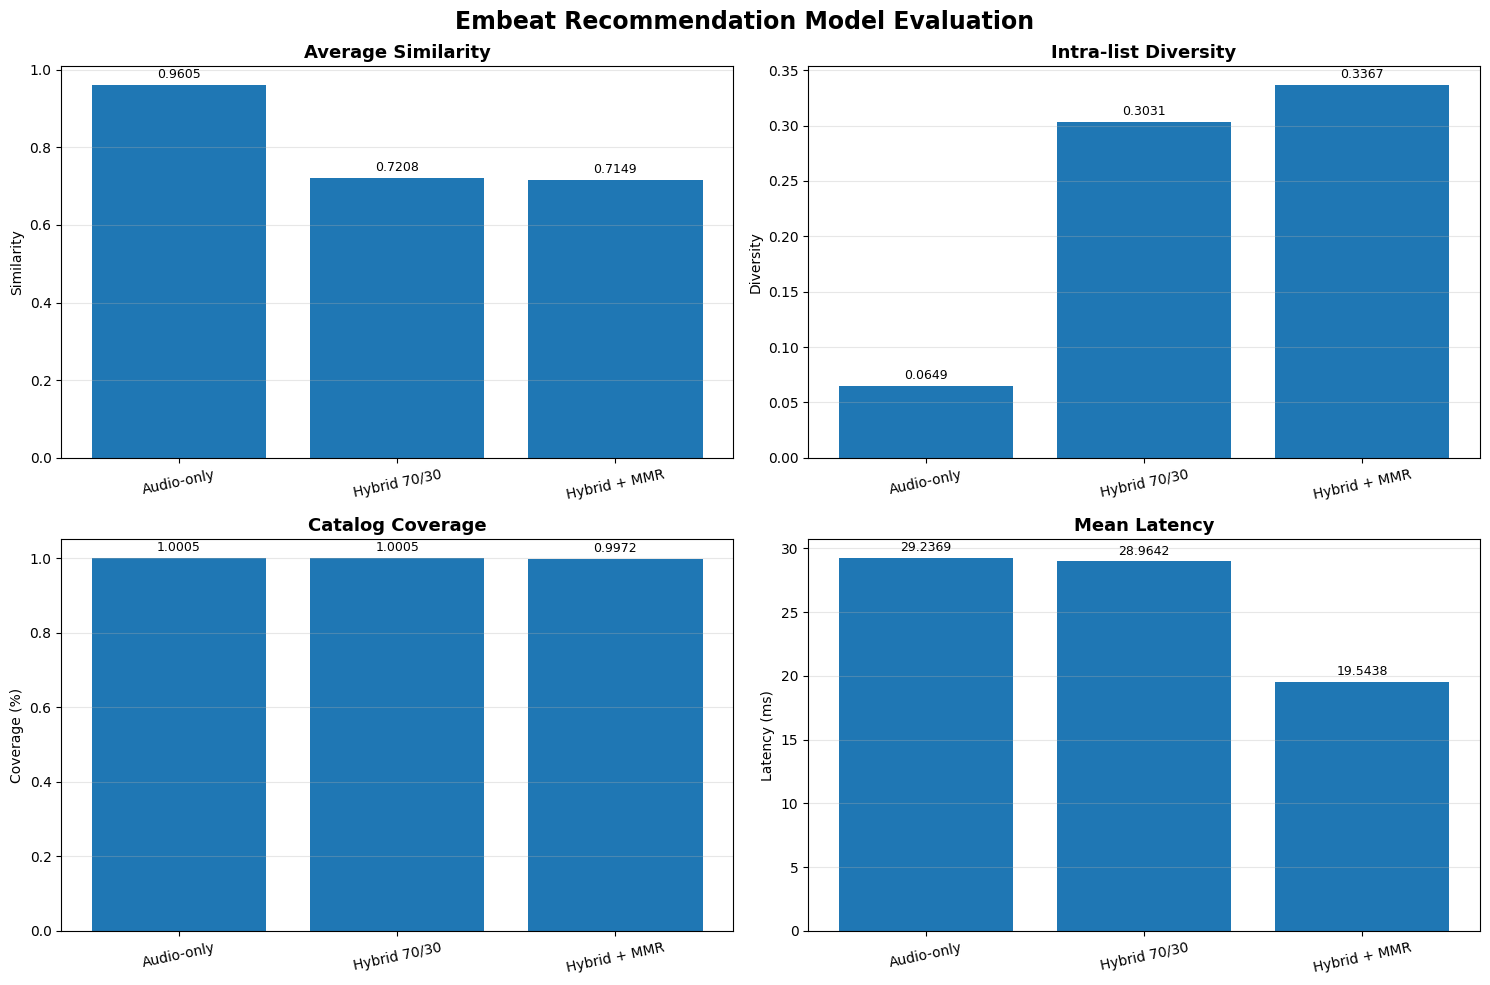


DASHBOARD GENERATED SUCCESSFULLY
Saved at: /content/drive/MyDrive/music_recommender_project/artifacts/evaluation_dashboard.png
DASHBOARD VALIDATION: PASS


In [35]:

import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================
# 1. LOAD EVALUATION METRICS
# ==========================================

PROJECT_ROOT = Path.cwd()

METRICS_PATH = PROJECT_ROOT / "artifacts" / "metrics.json"
OUTPUT_DIR = PROJECT_ROOT / "artifacts"

# Nếu notebook đang chạy ở thư mục khác,
# chỉnh PROJECT_ROOT về thư mục gốc của project.

if not METRICS_PATH.exists():
    raise FileNotFoundError(
        f"Không tìm thấy metrics.json tại: {METRICS_PATH}"
    )

with open(METRICS_PATH, "r", encoding="utf-8") as file:
    metrics = json.load(file)

summary_df = pd.DataFrame(metrics["results"])

print("METRICS LOADED SUCCESSFULLY")
print("Models:", summary_df["model"].tolist())

# ==========================================
# 2. PREPARE CHART DATA
# ==========================================

chart_metrics = [
    {
        "column": "avg_similarity",
        "title": "Average Similarity",
        "ylabel": "Similarity"
    },
    {
        "column": "intra_list_diversity",
        "title": "Intra-list Diversity",
        "ylabel": "Diversity"
    },
    {
        "column": "coverage_pct",
        "title": "Catalog Coverage",
        "ylabel": "Coverage (%)"
    },
    {
        "column": "mean_latency_ms",
        "title": "Mean Latency",
        "ylabel": "Latency (ms)"
    }
]

# ==========================================
# 3. CREATE DASHBOARD
# ==========================================

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(15, 10)
)

axes = axes.flatten()

for ax, metric in zip(axes, chart_metrics):

    bars = ax.bar(
        summary_df["model"],
        summary_df[metric["column"]]
    )

    ax.set_title(
        metric["title"],
        fontsize=13,
        fontweight="bold"
    )

    ax.set_ylabel(metric["ylabel"])
    ax.tick_params(axis="x", rotation=12)
    ax.grid(axis="y", alpha=0.3)

    # Hiển thị giá trị trên mỗi cột
    for bar in bars:
        value = bar.get_height()

        ax.annotate(
            f"{value:.4f}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                value
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

fig.suptitle(
    "Embeat Recommendation Model Evaluation",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

# ==========================================
# 4. SAVE AND DISPLAY
# ==========================================

OUTPUT_PATH = OUTPUT_DIR / "evaluation_dashboard.png"

plt.savefig(
    OUTPUT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nDASHBOARD GENERATED SUCCESSFULLY")
print("Saved at:", OUTPUT_PATH)

# ==========================================
# 5. VALIDATION
# ==========================================

assert OUTPUT_PATH.exists()
assert len(summary_df) == 3

print("DASHBOARD VALIDATION: PASS")


In [36]:

import os
import subprocess
import sys

os.chdir("/content/drive/MyDrive/music_recommender_project")

result = subprocess.run(
    [sys.executable, "-m", "src.evaluate"],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)

assert result.returncode == 0, "Evaluation failed"

print("TASK 2.3 EVALUATION: PASS")


Loaded: 29985 tracks; audio: (29985, 9) ; genres: (29985, 4211)
Evaluating: Audio-only
Evaluating: Hybrid 70/30
Evaluating: Hybrid + MMR
Evaluating: Random Baseline
Evaluating: Popularity Baseline
Dashboard: /content/drive/MyDrive/music_recommender_project/artifacts/evaluation_dashboard.png
              model  mean_audio_cosine  mean_acoustic_distance  audio_diversity  coverage_pct  mean_latency_ms
         Audio-only           0.960541                0.039459         0.064865      1.000500         5.245485
       Hybrid 70/30           0.929475                0.070525         0.096500      1.000500         9.988432
       Hybrid + MMR           0.936586                0.063414         0.111791      0.997165        12.966509
    Random Baseline           0.013582                0.986418         0.986175      0.997165         3.122187
Popularity Baseline           0.027189                0.972811         0.741555      0.033350         8.719220
EVALUATION COMPLETED SUCCESSFULLY

TASK 2.

In [40]:
import subprocess
import sys

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "src.train",
        "--help"
    ],
    capture_output=True,
    text=True,
    cwd=str(PROJECT_ROOT)
)

print("RETURN CODE:", result.returncode)

print("\n=== STDOUT ===")
print(result.stdout if result.stdout else "(Empty)")

print("\n=== STDERR ===")
print(result.stderr if result.stderr else "(Empty)")

assert result.returncode == 0, "CLI HELP VALIDATION FAILED"

print("\nCLI ARGUMENT VALIDATION: PASS")

RETURN CODE: 0

=== STDOUT ===
usage: train.py [-h] [--mode {csv,stream}] [--input INPUT] [--output OUTPUT]
                [--sample-ratio SAMPLE_RATIO]
                [--max-row-groups-per-file MAX_ROW_GROUPS_PER_FILE]
                [--max-total-tracks MAX_TOTAL_TRACKS]
                [--min-popularity MIN_POPULARITY] [--no-fallback]

Train Embeat Music Recommendation Model

options:
  -h, --help            show this help message and exit
  --mode {csv,stream}   Training mode: csv or stream
  --input INPUT         Path to input CSV dataset (CSV mode)
  --output OUTPUT       Path to save model artifact
  --sample-ratio SAMPLE_RATIO
                        Sampling ratio for streaming (1.0 = all data)
  --max-row-groups-per-file MAX_ROW_GROUPS_PER_FILE
                        Maximum row groups to process per Parquet file
  --max-total-tracks MAX_TOTAL_TRACKS
                        Maximum number of tracks to receive
  --min-popularity MIN_POPULARITY
                        Minimu

In [41]:
import subprocess
import sys

TEST_CLI_ARTIFACT = (
    PROJECT_ROOT / "artifacts" / "embeat_cli_test.joblib"
)

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "src.train",
        "--mode", "csv",
        "--input", str(SAMPLE_PATH),
        "--output", str(TEST_CLI_ARTIFACT),
    ],
    capture_output=True,
    text=True,
    cwd=str(PROJECT_ROOT)
)

print("RETURN CODE:", result.returncode)

print("\n=== STDOUT ===")
print(result.stdout)

print("\n=== STDERR ===")
print(result.stderr if result.stderr else "(Empty)")

assert result.returncode == 0, "CSV CLI TRAINING FAILED"
assert TEST_CLI_ARTIFACT.exists(), "ARTIFACT NOT CREATED"

print("\nCSV CLI TRAINING: PASS")

RETURN CODE: 0

=== STDOUT ===
EMBEAT TRAINING CLI
Training mode: csv
Output artifact: /content/drive/MyDrive/music_recommender_project/artifacts/embeat_cli_test.joblib

Starting CSV training...
EMBEAT MODEL TRAINING

[1/5] Loading dataset...
Original shape: (5000, 28)

[2/5] Training audio model...
Cleaned tracks: 4997
Audio matrix: (4997, 9)

[3/5] Building genre matrix...
Genre matrix: (4997, 1995)
Unique genres: 1995

[4/5] Saving model artifact...
Model saved successfully: /content/drive/MyDrive/music_recommender_project/artifacts/embeat_cli_test.joblib

[5/5] Generating training metadata...

TRAINING COMPLETED SUCCESSFULLY
{
    "model_name": "EmbeatRecommender",
    "total_tracks": 4997,
    "audio_features": 9,
    "total_genres": 1995,
    "genre_matrix_shape": [
        4997,
        1995
    ],
    "artifact_path": "/content/drive/MyDrive/music_recommender_project/artifacts/embeat_cli_test.joblib"
}

CLI TRAINING COMPLETED


=== STDERR ===
(Empty)

CSV CLI TRAINING: PASS


In [42]:
import subprocess
import sys

result = subprocess.run(
    [
        sys.executable,
        "-c",
        """
from src.recommender import EmbeatRecommender
import sys

model = EmbeatRecommender.load_artifact(sys.argv[1])

print("TRACKS:", len(model.df))
print("AUDIO MATRIX:", model.feature_matrix.shape)
print("GENRE MATRIX:", model.genre_matrix.shape)
print("UNIQUE TRACK IDS:", model.df["track_id"].nunique())

assert len(model.df) == 4997
assert model.feature_matrix.shape == (4997, 9)
assert model.genre_matrix.shape == (4997, 1995)
assert model.df["track_id"].is_unique

print("ARTIFACT RELOAD: PASS")
""",
        str(TEST_CLI_ARTIFACT),
    ],
    capture_output=True,
    text=True,
    cwd=str(PROJECT_ROOT)
)

print("RETURN CODE:", result.returncode)
print(result.stdout)
print(result.stderr if result.stderr else "(Empty STDERR)")

assert result.returncode == 0
assert "ARTIFACT RELOAD: PASS" in result.stdout

print("\nCLI ARTIFACT RELOAD VALIDATION: PASS")

RETURN CODE: 0
TRACKS: 4997
AUDIO MATRIX: (4997, 9)
GENRE MATRIX: (4997, 1995)
UNIQUE TRACK IDS: 4997
ARTIFACT RELOAD: PASS

(Empty STDERR)

CLI ARTIFACT RELOAD VALIDATION: PASS


In [46]:
import subprocess
import sys

TEST_STREAM_CLI_ARTIFACT = (
    PROJECT_ROOT / "artifacts" / "embeat_stream_cli_test.joblib"
)

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "src.train",
        "--mode", "stream",
        "--output", str(TEST_STREAM_CLI_ARTIFACT),
        "--sample-ratio", "1.0",
        "--max-total-tracks", "5000",
    ],
    capture_output=True,
    text=True,
    cwd=str(PROJECT_ROOT)
)

print("RETURN CODE:", result.returncode)

print("\n=== STDOUT ===")
print(result.stdout)

print("\n=== STDERR ===")
print(result.stderr if result.stderr else "(Empty)")

assert result.returncode == 0, "STREAM CLI TRAINING FAILED"
assert TEST_STREAM_CLI_ARTIFACT.exists(), "STREAM ARTIFACT NOT CREATED"

print("\nSTREAM CLI TRAINING: PASS")

RETURN CODE: 0

=== STDOUT ===
EMBEAT TRAINING CLI
Training mode: stream
Output artifact: /content/drive/MyDrive/music_recommender_project/artifacts/embeat_stream_cli_test.joblib

Starting Streaming training...
EMBEAT STREAMING BATCH TRAINING

[1/5] Receiving data batches...

[2/5] Finalizing accumulated batches...
=== FINALIZING BATCH TRAINING ===
Received batches: 5
Total input tracks: 4997
Cleaned tracks: 4997
Audio matrix: (4997, 9)
BATCH TRAINING COMPLETED

[3/5] Building genre matrix...
Genre matrix: (4997, 1995)
Unique genres: 1995

[4/5] Saving model artifact...
Model saved successfully: /content/drive/MyDrive/music_recommender_project/artifacts/embeat_stream_cli_test.joblib

[5/5] Generating training metadata...

STREAMING TRAINING COMPLETED
{
    "model_name": "EmbeatRecommender",
    "training_method": "batch_accumulation",
    "total_tracks": 4997,
    "audio_features": 9,
    "total_genres": 1995,
    "audio_matrix_shape": [
        4997,
        9
    ],
    "genre_matrix

In [45]:
import subprocess
import sys

result = subprocess.run(
    [
        sys.executable,
        "-c",
        """
from src.recommender import EmbeatRecommender
import sys

model = EmbeatRecommender.load_artifact(sys.argv[1])

print("TRACKS:", len(model.df))
print("AUDIO:", model.feature_matrix.shape)
print("GENRES:", model.genre_matrix.shape)
print("UNIQUE IDS:", model.df["track_id"].nunique())

assert len(model.df) == 4997
assert model.feature_matrix.shape == (4997, 9)
assert model.genre_matrix.shape == (4997, 1995)
assert model.df["track_id"].is_unique

print("STREAM ARTIFACT RELOAD: PASS")
""",
        str(TEST_STREAM_CLI_ARTIFACT),
    ],
    capture_output=True,
    text=True,
    cwd=str(PROJECT_ROOT)
)

print("RETURN CODE:", result.returncode)
print(result.stdout)
print(result.stderr if result.stderr else "(Empty STDERR)")

assert result.returncode == 0
assert "STREAM ARTIFACT RELOAD: PASS" in result.stdout

print("STREAM CLI ARTIFACT VALIDATION: PASS")

RETURN CODE: 0
TRACKS: 4997
AUDIO: (4997, 9)
GENRES: (4997, 1995)
UNIQUE IDS: 4997
STREAM ARTIFACT RELOAD: PASS

(Empty STDERR)
STREAM CLI ARTIFACT VALIDATION: PASS


In [47]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error

# 1. Lấy dữ liệu hiện tại
source_df = main_model.df.copy()

# 2. Chia dữ liệu thành 5 batch
batches = np.array_split(source_df, 5)

print("Total tracks:", len(source_df))
print("Number of batches:", len(batches))
print("Batch sizes:", [len(batch) for batch in batches])

# 3. Huấn luyện trực tiếp trên toàn bộ dữ liệu
full_model = EmbeatRecommender()
full_model.fit(source_df)

# 4. Huấn luyện thông qua nhiều batch
batch_model = EmbeatRecommender()

for i, batch in enumerate(batches):
    batch_model.fit_incremental(
        batch,
        is_first_batch=(i == 0)
    )

batch_model.finalize_incremental_training()

# 5. So sánh kết quả
pd.testing.assert_frame_equal(
    full_model.df,
    batch_model.df
)

np.testing.assert_allclose(
    full_model.feature_matrix,
    batch_model.feature_matrix,
    rtol=1e-6,
    atol=1e-6
)

np.testing.assert_allclose(
    full_model.scaler.mean_,
    batch_model.scaler.mean_,
    rtol=1e-6,
    atol=1e-6
)

np.testing.assert_allclose(
    full_model.scaler.scale_,
    batch_model.scaler.scale_,
    rtol=1e-6,
    atol=1e-6
)

assert full_model.id_to_idx == batch_model.id_to_idx

print("\nBATCH TRAINING CONSISTENCY: PASS")
print("DATAFRAME: PASS")
print("AUDIO MATRIX: PASS")
print("SCALER: PASS")
print("TRACK INDEX: PASS")


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:54: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


Total tracks: 29985
Number of batches: 5
Batch sizes: [5997, 5997, 5997, 5997, 5997]
=== FINALIZING BATCH TRAINING ===
Received batches: 5
Total input tracks: 29985
Cleaned tracks: 29985
Audio matrix: (29985, 9)
BATCH TRAINING COMPLETED

BATCH TRAINING CONSISTENCY: PASS
DATAFRAME: PASS
AUDIO MATRIX: PASS
SCALER: PASS
TRACK INDEX: PASS


In [50]:

from pathlib import Path
import sys
import importlib

# Thư mục gốc dự án
PROJECT_ROOT = Path("/content/drive/MyDrive/music_recommender_project")

# Đảm bảo Python tìm được package src
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Đường dẫn model và thư mục báo cáo
ARTIFACT_PATH = PROJECT_ROOT / "artifacts" / "embeat_recommender.joblib"
REPORTS_DIR = PROJECT_ROOT / "reports"

# Tạo thư mục reports nếu chưa tồn tại
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Kiểm tra model
assert ARTIFACT_PATH.exists(), f"Không tìm thấy model: {ARTIFACT_PATH}"

print("Project:", PROJECT_ROOT)
print("Artifact:", ARTIFACT_PATH)
print("Reports:", REPORTS_DIR)
print("Configuration: PASS")


Project: /content/drive/MyDrive/music_recommender_project
Artifact: /content/drive/MyDrive/music_recommender_project/artifacts/embeat_recommender.joblib
Reports: /content/drive/MyDrive/music_recommender_project/reports
Configuration: PASS


In [51]:

import importlib
import src.evaluate as evaluation

importlib.reload(evaluation)

evaluation.ARTIFACT_PATH = ARTIFACT_PATH
evaluation.OUTPUT_DIR = REPORTS_DIR

evaluation.main()


Loaded: 29985 tracks; audio: (29985, 9) ; genres: (29985, 4211)
Evaluating: Audio-only
Evaluating: Hybrid 70/30
Evaluating: Hybrid + MMR
Evaluating: Random Baseline
Evaluating: Popularity Baseline
Dashboard saved: /content/drive/MyDrive/music_recommender_project/reports/figures/evaluation_dashboard.png
              model  mean_audio_cosine  mean_acoustic_distance  audio_diversity  coverage_pct  mean_latency_ms
         Audio-only           0.960541                0.039459         0.064865      1.000500         5.418214
       Hybrid 70/30           0.929475                0.070525         0.096500      1.000500        10.130814
       Hybrid + MMR           0.936586                0.063414         0.111791      0.997165        12.343771
    Random Baseline           0.013582                0.986418         0.986175      0.997165         4.307634
Popularity Baseline           0.027189                0.972811         0.741555      0.033350        14.350392
EVALUATION COMPLETED SUCCESSFU

In [52]:

required_files = [
    REPORTS_DIR / "metrics.json",
    REPORTS_DIR / "evaluation_summary.csv",
    REPORTS_DIR / "evaluation_details.csv",
    REPORTS_DIR / "figures" / "evaluation_dashboard.png"
]

print("=== TASK 2.3 OUTPUT VALIDATION ===")

for path in required_files:
    print(path.name, "EXISTS:", path.exists())
    assert path.exists(), f"Missing: {path}"

print("\nTASK 2.3 OUTPUT VALIDATION: PASS")


=== TASK 2.3 OUTPUT VALIDATION ===
metrics.json EXISTS: True
evaluation_summary.csv EXISTS: True
evaluation_details.csv EXISTS: True
evaluation_dashboard.png EXISTS: True

TASK 2.3 OUTPUT VALIDATION: PASS


In [53]:

from pathlib import Path

ARTIFACT_DIR = PROJECT_ROOT / "artifacts"

print("=== ARTIFACT INVENTORY ===")

for path in sorted(ARTIFACT_DIR.iterdir()):
    if path.is_file():
        print(
            path.name,
            "|",
            round(path.stat().st_size / (1024 ** 2), 3),
            "MB"
        )

print("\n=== REPORT INVENTORY ===")

for path in sorted(REPORTS_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(REPORTS_DIR))


=== ARTIFACT INVENTORY ===
embeat_batch_test.joblib | 0.956 MB
embeat_cli_test.joblib | 0.956 MB
embeat_recommender.joblib | 5.097 MB
embeat_stream_cli_test.joblib | 0.956 MB
embeat_stream_test.joblib | 0.956 MB
evaluation_dashboard.png | 0.318 MB
evaluation_details.csv | 0.384 MB
evaluation_summary.csv | 0.002 MB
metrics.json | 0.007 MB
training_metadata.json | 0.0 MB

=== REPORT INVENTORY ===
evaluation_dashboard.png
evaluation_details.csv
evaluation_summary.csv
figures/evaluation_dashboard.png
metrics.json


In [54]:

import json
from pathlib import Path

METADATA_PATH = ARTIFACT_DIR / "training_metadata.json"

print("=== TRAINING METADATA ===")

assert METADATA_PATH.exists(), "Không tìm thấy training_metadata.json"

with open(METADATA_PATH, "r", encoding="utf-8") as f:
    training_metadata = json.load(f)

print(json.dumps(
    training_metadata,
    indent=4,
    ensure_ascii=False
))

print("\n=== METADATA VALIDATION ===")

print("Model name:", training_metadata.get("model_name"))
print("Total tracks:", training_metadata.get("total_tracks"))
print("Audio features:", training_metadata.get("audio_features"))
print("Total genres:", training_metadata.get("total_genres"))
print("Artifact path:", training_metadata.get("artifact_path"))


=== TRAINING METADATA ===
{
    "model_name": "EmbeatRecommender",
    "training_method": "batch_accumulation",
    "total_tracks": 4997,
    "audio_features": 9,
    "total_genres": 1995,
    "audio_matrix_shape": [
        4997,
        9
    ],
    "genre_matrix_shape": [
        4997,
        1995
    ],
    "artifact_path": "/content/drive/MyDrive/music_recommender_project/artifacts/embeat_stream_cli_test.joblib",
    "sample_ratio": 1.0,
    "max_total_tracks": 5000
}

=== METADATA VALIDATION ===
Model name: EmbeatRecommender
Total tracks: 4997
Audio features: 9
Total genres: 1995
Artifact path: /content/drive/MyDrive/music_recommender_project/artifacts/embeat_stream_cli_test.joblib


In [55]:

import json
from datetime import datetime, timezone

# MAIN_ARTIFACT là đường dẫn model chính đã kiểm tra
MAIN_ARTIFACT = PROJECT_ROOT / "artifacts" / "embeat_recommender.joblib"

assert MAIN_ARTIFACT.exists(), "Không tìm thấy artifact chính"

# Đọc trực tiếp model chính để lấy thông tin thực tế
main_model = EmbeatRecommender.load_artifact(str(MAIN_ARTIFACT))

main_metadata = {
    "model_name": "EmbeatRecommender",
    "training_method": "batch",
    "total_tracks": len(main_model.df),
    "audio_features": main_model.feature_matrix.shape[1],
    "total_genres": main_model.genre_matrix.shape[1],
    "audio_matrix_shape": list(main_model.feature_matrix.shape),
    "genre_matrix_shape": list(main_model.genre_matrix.shape),
    "artifact_path": str(MAIN_ARTIFACT),
    "artifact_filename": MAIN_ARTIFACT.name,
    "metadata_generated_at": datetime.now(timezone.utc).isoformat()
}

# Kiểm tra model chính trước khi ghi
assert main_metadata["total_tracks"] == 29985
assert main_metadata["audio_features"] == 9
assert main_metadata["total_genres"] == 4211
assert main_model.df["track_id"].is_unique

MAIN_METADATA_PATH = (
    PROJECT_ROOT / "artifacts" / "main_model_metadata.json"
)

with open(MAIN_METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(main_metadata, f, indent=4, ensure_ascii=False)

print(json.dumps(main_metadata, indent=4, ensure_ascii=False))
print("\nMAIN MODEL METADATA: PASS")
print("Saved to:", MAIN_METADATA_PATH)


{
    "model_name": "EmbeatRecommender",
    "training_method": "batch",
    "total_tracks": 29985,
    "audio_features": 9,
    "total_genres": 4211,
    "audio_matrix_shape": [
        29985,
        9
    ],
    "genre_matrix_shape": [
        29985,
        4211
    ],
    "artifact_path": "/content/drive/MyDrive/music_recommender_project/artifacts/embeat_recommender.joblib",
    "artifact_filename": "embeat_recommender.joblib",
    "metadata_generated_at": "2026-11-08T10:22:01.871817+00:00"
}

MAIN MODEL METADATA: PASS
Saved to: /content/drive/MyDrive/music_recommender_project/artifacts/main_model_metadata.json


In [56]:

import ast
from pathlib import Path

TRAIN_PATH = PROJECT_ROOT / "src" / "train.py"

# 1. Kiểm tra cú pháp
source = TRAIN_PATH.read_text(encoding="utf-8")
ast.parse(source)

print("PYTHON SYNTAX: PASS")

# 2. Kiểm tra tên metadata
main_output = PROJECT_ROOT / "artifacts" / "embeat_recommender.joblib"
test_output = PROJECT_ROOT / "artifacts" / "embeat_stream_cli_test.joblib"

main_metadata = main_output.with_name(
    f"{main_output.stem}_metadata.json"
)

test_metadata = test_output.with_name(
    f"{test_output.stem}_metadata.json"
)

print("Main metadata:", main_metadata.name)
print("Test metadata:", test_metadata.name)

assert main_metadata.name == "embeat_recommender_metadata.json"
assert test_metadata.name == "embeat_stream_cli_test_metadata.json"
assert main_metadata != test_metadata

print("METADATA PATH VALIDATION: PASS")


PYTHON SYNTAX: PASS
Main metadata: embeat_recommender_metadata.json
Test metadata: embeat_stream_cli_test_metadata.json
METADATA PATH VALIDATION: PASS


In [57]:

GITIGNORE_PATH = PROJECT_ROOT / ".gitignore"

print("=== GITIGNORE CONTENT ===")

if GITIGNORE_PATH.exists():
    print(GITIGNORE_PATH.read_text(encoding="utf-8"))
else:
    print("Không tìm thấy .gitignore")

print("\n=== GIT STATUS ===")

import subprocess

result = subprocess.run(
    ["git", "status", "--short"],
    cwd=str(PROJECT_ROOT),
    capture_output=True,
    text=True
)

print(result.stdout if result.stdout else "Working tree clean")


=== GITIGNORE CONTENT ===
# Byte-compiled / optimized / DLL files
__pycache__/
*.py[cod]
*$py.class

# Virtual environments
.venv/
venv/
env/

# Environment variables & Secrets (NEVER commit tokens)
.env

# Large Model Artifacts (>100MB GitHub limit)
models/*.pkl
models/*.bin
models/*.faiss
models/*.ann

# Raw large datasets (keep sample_tracks.csv and quality reports)
data/raw/*
!data/raw/.gitkeep
data/processed/*.parquet

# Jupyter Notebook checkpoints
.ipynb_checkpoints/
*/.ipynb_checkpoints/

# IDE & OS files
.vscode/
.idea/
.DS_Store
Thumbs.db
# Generated model artifacts
artifacts/*.joblib
artifacts/*.pkl


=== GIT STATUS ===
 M .gitignore
 M data/processed/sample_tracks.csv
 M src/preprocess.py
?? artifacts/
?? data/processed/balanced_eda.csv
?? notebooks/03_train_model.ipynb
?? notebooks/04_evaluate_model.ipynb
?? reports/
?? src/evaluate.py
?? src/recommender.py
?? src/train.py



In [61]:
!git check-ignore -v artifacts/embeat_recommender.joblib
!git check-ignore -v artifacts/embeat_batch_test.joblib
!git status --short


.gitignore:37:!artifacts/embeat_recommender.joblib	artifacts/embeat_recommender.joblib
.gitignore:36:artifacts/*.joblib	artifacts/embeat_batch_test.joblib
 M .gitignore
 M data/processed/sample_tracks.csv
 M src/preprocess.py
?? artifacts/
?? data/processed/balanced_eda.csv
?? notebooks/03_train_model.ipynb
?? notebooks/04_evaluate_model.ipynb
?? reports/
?? src/evaluate.py
?? src/recommender.py
?? src/train.py


In [62]:
!git status --short --untracked-files=all

 M .gitignore
 M data/processed/sample_tracks.csv
 M src/preprocess.py
?? artifacts/embeat_recommender.joblib
?? artifacts/evaluation_dashboard.png
?? artifacts/evaluation_details.csv
?? artifacts/evaluation_summary.csv
?? artifacts/main_model_metadata.json
?? artifacts/metrics.json
?? artifacts/training_metadata.json
?? data/processed/balanced_eda.csv
?? notebooks/03_train_model.ipynb
?? notebooks/04_evaluate_model.ipynb
?? reports/evaluation_dashboard.png
?? reports/evaluation_details.csv
?? reports/evaluation_summary.csv
?? reports/figures/evaluation_dashboard.png
?? reports/metrics.json
?? src/evaluate.py
?? src/recommender.py
?? src/train.py


In [63]:
from pathlib import Path

files_to_check = [
    PROJECT_ROOT / "data/processed/sample_tracks.csv",
    PROJECT_ROOT / "data/processed/balanced_eda.csv",
    PROJECT_ROOT / "artifacts/embeat_recommender.joblib",
    PROJECT_ROOT / "artifacts/main_model_metadata.json",
    PROJECT_ROOT / "artifacts/training_metadata.json",
]

print("=== FILE SIZE CHECK ===")

for path in files_to_check:
    if path.exists():
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"{path.name}: {size_mb:.2f} MB")
    else:
        print(f"{path.name}: NOT FOUND")

=== FILE SIZE CHECK ===
sample_tracks.csv: 1.78 MB
balanced_eda.csv: 10.82 MB
embeat_recommender.joblib: 5.10 MB
main_model_metadata.json: 0.00 MB
training_metadata.json: 0.00 MB


In [64]:
import pandas as pd

sample_path = PROJECT_ROOT / "data/processed/sample_tracks.csv"
balanced_path = PROJECT_ROOT / "data/processed/balanced_eda.csv"

sample_df = pd.read_csv(sample_path)
balanced_df = pd.read_csv(balanced_path)

print("=== DATASET COMPARISON ===")

print("Sample shape:", sample_df.shape)
print("Balanced shape:", balanced_df.shape)

print(
    "Sample unique Track IDs:",
    sample_df["track_id"].nunique()
)

print(
    "Balanced unique Track IDs:",
    balanced_df["track_id"].nunique()
)

print(
    "Sample IDs contained in Balanced:",
    sample_df["track_id"].isin(
        balanced_df["track_id"]
    ).sum()
)

print(
    "Balanced columns match Sample:",
    set(sample_df.columns) == set(balanced_df.columns)
)

=== DATASET COMPARISON ===
Sample shape: (5000, 28)
Balanced shape: (30000, 28)
Sample unique Track IDs: 5000
Balanced unique Track IDs: 30000
Sample IDs contained in Balanced: 5000
Balanced columns match Sample: True


In [65]:
# Kiểm tra dữ liệu của 5.000 Track ID chung

sample_sorted = (
    sample_df
    .sort_values("track_id")
    .reset_index(drop=True)
)

balanced_subset = (
    balanced_df[
        balanced_df["track_id"].isin(sample_df["track_id"])
    ]
    .sort_values("track_id")
    .reset_index(drop=True)
)

pd.testing.assert_frame_equal(
    sample_sorted,
    balanced_subset,
    check_dtype=False,
    check_like=False
)

print("SAMPLE DATA CONSISTENCY: PASS")
print("All 5,000 shared records are identical.")

SAMPLE DATA CONSISTENCY: PASS
All 5,000 shared records are identical.


In [66]:
# Kiểm tra dữ liệu huấn luyện và model chính

print("=== TRAINING DATA VALIDATION ===")

print("Balanced EDA rows:", len(balanced_df))
print("Main model tracks:", len(main_model.df))

print(
    "Model Track IDs contained in Balanced EDA:",
    main_model.df["track_id"].isin(
        balanced_df["track_id"]
    ).sum()
)

print(
    "Model tracks missing from Balanced EDA:",
    (~main_model.df["track_id"].isin(
        balanced_df["track_id"]
    )).sum()
)

print(
    "Model training data is subset of Balanced EDA:",
    main_model.df["track_id"].isin(
        balanced_df["track_id"]
    ).all()
)

=== TRAINING DATA VALIDATION ===
Balanced EDA rows: 30000
Main model tracks: 29985
Model Track IDs contained in Balanced EDA: 29985
Model tracks missing from Balanced EDA: 0
Model training data is subset of Balanced EDA: True


In [67]:
import hashlib
from pathlib import Path

def file_hash(path):
    sha = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(chunk)

    return sha.hexdigest()


pairs = [
    (
        PROJECT_ROOT / "artifacts/evaluation_dashboard.png",
        REPORTS_DIR / "evaluation_dashboard.png"
    ),
    (
        PROJECT_ROOT / "artifacts/evaluation_details.csv",
        REPORTS_DIR / "evaluation_details.csv"
    ),
    (
        PROJECT_ROOT / "artifacts/evaluation_summary.csv",
        REPORTS_DIR / "evaluation_summary.csv"
    ),
    (
        PROJECT_ROOT / "artifacts/metrics.json",
        REPORTS_DIR / "metrics.json"
    )
]

print("=== DUPLICATE FILE CHECK ===")

for file_a, file_b in pairs:
    if file_a.exists() and file_b.exists():
        same = file_hash(file_a) == file_hash(file_b)

        print(
            f"{file_a.name}:",
            "IDENTICAL" if same else "DIFFERENT"
        )
    else:
        print(f"{file_a.name}: MISSING FILE")

=== DUPLICATE FILE CHECK ===
evaluation_dashboard.png: DIFFERENT
evaluation_details.csv: IDENTICAL
evaluation_summary.csv: DIFFERENT
metrics.json: DIFFERENT


In [68]:
evaluation.ARTIFACT_PATH = ARTIFACT_PATH
evaluation.OUTPUT_DIR = REPORTS_DIR

evaluation.main()

Loaded: 29985 tracks; audio: (29985, 9) ; genres: (29985, 4211)
Evaluating: Audio-only
Evaluating: Hybrid 70/30
Evaluating: Hybrid + MMR
Evaluating: Random Baseline
Evaluating: Popularity Baseline
Dashboard saved: /content/drive/MyDrive/music_recommender_project/reports/figures/evaluation_dashboard.png
              model  mean_audio_cosine  mean_acoustic_distance  audio_diversity  coverage_pct  mean_latency_ms
         Audio-only           0.960541                0.039459         0.064865      1.000500        11.075701
       Hybrid 70/30           0.929475                0.070525         0.096500      1.000500        13.720772
       Hybrid + MMR           0.936586                0.063414         0.111791      0.997165        12.928053
    Random Baseline           0.013582                0.986418         0.986175      0.997165         3.620022
Popularity Baseline           0.027189                0.972811         0.741555      0.033350        10.377999
EVALUATION COMPLETED SUCCESSFU

In [69]:
import json
from pathlib import Path

artifact_metrics = PROJECT_ROOT / "artifacts/metrics.json"
report_metrics = REPORTS_DIR / "metrics.json"

print("=== EVALUATION FILE COMPARISON ===")

for path in [artifact_metrics, report_metrics]:
    if path.exists():
        print("\nFile:", path)
        print("Modified:", path.stat().st_mtime)

        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        print("Evaluation config:", data.get("evaluation_config"))
        print("Catalog size:", data.get("catalog_size"))

=== EVALUATION FILE COMPARISON ===

File: /content/drive/MyDrive/music_recommender_project/artifacts/metrics.json
Modified: 1794131462.0
Evaluation config: {'n_queries': 30, 'top_n': 10, 'alpha': 0.7, 'mmr_lambda': 0.7, 'candidate_pool': 50, 'random_state': 42}
Catalog size: 29985

File: /content/drive/MyDrive/music_recommender_project/reports/metrics.json
Modified: 1794133984.0
Evaluation config: {'n_queries': 30, 'top_n': 10, 'alpha': 0.7, 'mmr_lambda': 0.7, 'candidate_pool': 50, 'random_state': 42}
Catalog size: 29985


In [70]:
from pathlib import Path

old_files = [
    PROJECT_ROOT / "artifacts/evaluation_dashboard.png",
    PROJECT_ROOT / "artifacts/evaluation_details.csv",
    PROJECT_ROOT / "artifacts/evaluation_summary.csv",
    PROJECT_ROOT / "artifacts/metrics.json",
]

print("=== OLD EVALUATION ARTIFACTS ===")

for path in old_files:
    if path.exists():
        print(path.name, "EXISTS")
    else:
        print(path.name, "NOT FOUND")

=== OLD EVALUATION ARTIFACTS ===
evaluation_dashboard.png EXISTS
evaluation_details.csv EXISTS
evaluation_summary.csv EXISTS
metrics.json EXISTS


In [71]:
for path in old_files:
    if path.exists():
        path.unlink()
        print("Removed:", path.name)

print("OLD EVALUATION FILES CLEANUP: PASS")

Removed: evaluation_dashboard.png
Removed: evaluation_details.csv
Removed: evaluation_summary.csv
Removed: metrics.json
OLD EVALUATION FILES CLEANUP: PASS


In [72]:
import subprocess

result = subprocess.run(
    ["git", "status", "--short", "--untracked-files=all"],
    cwd=str(PROJECT_ROOT),
    capture_output=True,
    text=True
)

print(result.stdout)
assert result.returncode == 0

print("GIT STATUS CHECK: PASS")

 M .gitignore
 M data/processed/sample_tracks.csv
 M src/preprocess.py
?? artifacts/embeat_recommender.joblib
?? artifacts/main_model_metadata.json
?? artifacts/training_metadata.json
?? data/processed/balanced_eda.csv
?? notebooks/03_train_model.ipynb
?? notebooks/04_evaluate_model.ipynb
?? reports/evaluation_dashboard.png
?? reports/evaluation_details.csv
?? reports/evaluation_summary.csv
?? reports/figures/evaluation_dashboard.png
?? reports/metrics.json
?? src/evaluate.py
?? src/recommender.py
?? src/train.py

GIT STATUS CHECK: PASS


In [73]:
import subprocess

files = [
    ".gitignore",
    "src/preprocess.py",
    "data/processed/sample_tracks.csv"
]

for file in files:
    print(f"\n{'=' * 20} {file} {'=' * 20}")

    result = subprocess.run(
        ["git", "diff", "--stat", "--", file],
        cwd=str(PROJECT_ROOT),
        capture_output=True,
        text=True
    )

    print(result.stdout or "No diff")


==================== .gitignore ====================
 .gitignore | 49 ++++++++++++++++++++++++++++++++-----------------
 1 file changed, 32 insertions(+), 17 deletions(-)


==================== src/preprocess.py ====================
 src/preprocess.py | 304 +++++++++++++++++++-----------------------------------
 1 file changed, 108 insertions(+), 196 deletions(-)


==================== data/processed/sample_tracks.csv ====================
 data/processed/sample_tracks.csv | 10002 ++++++++++++++++++-------------------
 1 file changed, 5001 insertions(+), 5001 deletions(-)



In [74]:
from pathlib import Path

check_dirs = [
    PROJECT_ROOT / "notebooks",
    PROJECT_ROOT / "reports"
]

print("=== NOTEBOOK & REPORT INVENTORY ===")

for directory in check_dirs:
    print(f"\n[{directory.name}]")

    for path in sorted(directory.rglob("*")):
        if path.is_file() and ".ipynb_checkpoints" not in str(path):
            size_mb = path.stat().st_size / (1024 ** 2)
            print(f"{path.relative_to(PROJECT_ROOT)}: {size_mb:.2f} MB")

=== NOTEBOOK & REPORT INVENTORY ===

[notebooks]
notebooks/01_explore_data.ipynb: 0.01 MB
notebooks/02_preprocess_data.ipynb: 0.00 MB
notebooks/03_train_model.ipynb: 0.30 MB
notebooks/04_evaluate_model.ipynb: 0.24 MB

[reports]
reports/evaluation_dashboard.png: 0.32 MB
reports/evaluation_details.csv: 0.38 MB
reports/evaluation_summary.csv: 0.00 MB
reports/figures/evaluation_dashboard.png: 0.46 MB
reports/metrics.json: 0.01 MB


In [75]:
import subprocess

result = subprocess.run(
    ["git", "diff", "--", "src/preprocess.py"],
    cwd=str(PROJECT_ROOT),
    capture_output=True,
    text=True
)

print(result.stdout[:20000])

diff --git a/src/preprocess.py b/src/preprocess.py
index 2574bfa..bc7af19 100644
--- a/src/preprocess.py
+++ b/src/preprocess.py
@@ -1,227 +1,139 @@
 
-import os
-import json
-import logging
-from typing import Dict, Any, Optional
-import numpy as np
 import pandas as pd
+from sklearn.preprocessing import StandardScaler
 
-logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s")
 
-# 9 Đặc trưng âm học cốt lõi phục vụ tính toán vector tương đồng (Cosine Similarity)
-CORE_AUDIO_FEATURES = [
+AUDIO_FEATURES = [
     "danceability",
     "energy",
     "valence",
     "tempo",
     "acousticness",
     "instrumentalness",
-    "liveness",
     "speechiness",
-    "loudness",
+    "liveness",
+    "loudness"
 ]
 
-# 3 Đặc trưng cấu trúc nhạc lý bổ trợ (Đủ 12 Audio Features chuẩn Spotify)
-STRUCTURAL_AUDIO_FEATURES = [
-    "key",
-    "mode",
-    "time_signature",
-]
 
-ALL_12_AUDIO_FEATURES = CORE_AUDIO_FEATURES + STRUCTURAL_AUDIO_FEATURES
+def clean_trac

In [76]:
result = subprocess.run(
    ["git", "diff", "--numstat", "--",
     "data/processed/sample_tracks.csv"],
    cwd=str(PROJECT_ROOT),
    capture_output=True,
    text=True
)

print(result.stdout)

5001	5001	data/processed/sample_tracks.csv



In [77]:
import subprocess

result = subprocess.run(
    [
        "git", "diff",
        "--ignore-space-at-eol",
        "--numstat",
        "--",
        "data/processed/sample_tracks.csv"
    ],
    cwd=str(PROJECT_ROOT),
    capture_output=True,
    text=True
)

print(result.stdout)

5001	5001	data/processed/sample_tracks.csv



In [78]:
result = subprocess.run(
    [
        "git", "diff",
        "--",
        "data/processed/sample_tracks.csv"
    ],
    cwd=str(PROJECT_ROOT),
    capture_output=True,
    text=True
)

print(result.stdout[:5000])

diff --git a/data/processed/sample_tracks.csv b/data/processed/sample_tracks.csv
index 3783670..6c99dd8 100644
--- a/data/processed/sample_tracks.csv
+++ b/data/processed/sample_tracks.csv
@@ -1,5001 +1,5001 @@
-track_id,track_name,artist_name,artist_genres,popularity,danceability,energy,valence,tempo,acousticness,instrumentalness,liveness,speechiness,loudness,key,mode,time_signature
-0VjIjW4GlUZAMYd2vXMi3b,Blinding Lights,The Weeknd,"canadian contemporary r&b, pop",95,0.514,0.73,0.334,171.005,0.0015,0.0001,0.0897,0.0598,-5.934,1,1,4
-7qiZfU4dY1lWllzX7mPBI3,Shape of You,Ed Sheeran,"pop, uk pop",92,0.825,0.652,0.931,95.977,0.581,0.0,0.0931,0.0802,-3.183,1,0,4
-4Dvkj6JhhA12EX05fT7y2e,As It Was,Harry Styles,pop,93,0.52,0.731,0.662,173.93,0.342,0.001,0.311,0.0557,-5.338,6,0,4
-32OlwWuMpZ6b0aN2RZOeMS,Uptown Funk,"Mark Ronson, Bruno Mars","funk, pop, dance pop",90,0.856,0.609,0.928,114.988,0.008,0.0001,0.0344,0.0824,-7.223,0,1,4
-2Fxmhks0bxGSBdJ92vM42m,bad guy,Billie Eilish,"art pop, electro

In [79]:
import subprocess
import pandas as pd
from io import StringIO

CSV_PATH = "data/processed/sample_tracks.csv"

# Lấy phiên bản CSV đang được Git lưu
result = subprocess.run(
    ["git", "show", f"HEAD:{CSV_PATH}"],
    cwd=str(PROJECT_ROOT),
    capture_output=True,
    text=True,
    encoding="utf-8"
)

assert result.returncode == 0, result.stderr

old_df = pd.read_csv(StringIO(result.stdout))
new_df = pd.read_csv(PROJECT_ROOT / CSV_PATH)

print("=== OLD VS NEW DATASET ===")

print("Old shape:", old_df.shape)
print("New shape:", new_df.shape)

print("\nOld columns:")
print(old_df.columns.tolist())

print("\nNew columns:")
print(new_df.columns.tolist())

print("\n=== TRACK ID COMPARISON ===")

old_ids = set(old_df["track_id"].dropna())
new_ids = set(new_df["track_id"].dropna())

print("Old unique IDs:", len(old_ids))
print("New unique IDs:", len(new_ids))
print("Shared IDs:", len(old_ids & new_ids))
print("Only in old:", len(old_ids - new_ids))
print("Only in new:", len(new_ids - old_ids))

print("\n=== FIRST 5 ROWS ===")

print("OLD:")
display(old_df.head())

print("NEW:")
display(new_df.head())

=== OLD VS NEW DATASET ===
Old shape: (5000, 17)
New shape: (5000, 28)

Old columns:
['track_id', 'track_name', 'artist_name', 'artist_genres', 'popularity', 'danceability', 'energy', 'valence', 'tempo', 'acousticness', 'instrumentalness', 'liveness', 'speechiness', 'loudness', 'key', 'mode', 'time_signature']

New columns:
['track_id', 'track_name', 'isrc', 'popularity', 'explicit', 'artist_idx', 'artist_id', 'artist_name', 'artist_popularity', 'artist_genres', 'artist_genre_idx', 'album_id', 'album_name', 'release_year', 'duration', 'time_signature', 'tempo', 'key', 'mode', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'source_shard']

=== TRACK ID COMPARISON ===
Old unique IDs: 5000
New unique IDs: 5000
Shared IDs: 0
Only in old: 5000
Only in new: 5000

=== FIRST 5 ROWS ===
OLD:


,track_id,track_name,artist_name,artist_genres,popularity,danceability,energy,valence,tempo,acousticness,instrumentalness,liveness,speechiness,loudness,key,mode,time_signature
0,0VjIjW4GlUZAMYd2vXMi3b,Blinding Lights,The Weeknd,"canadian contemporary r&b, pop",95,0.514,0.730,0.334,171.005,0.0015,0.0001,0.0897,0.0598,-5.934,1,1,4
1,7qiZfU4dY1lWllzX7mPBI3,Shape of You,Ed Sheeran,"pop, uk pop",92,0.825,0.652,0.931,95.977,0.5810,0.0000,0.0931,0.0802,-3.183,1,0,4
2,4Dvkj6JhhA12EX05fT7y2e,As It Was,Harry Styles,pop,93,0.520,0.731,0.662,173.930,0.3420,0.0010,0.3110,0.0557,-5.338,6,0,4
3,32OlwWuMpZ6b0aN2RZOeMS,Uptown Funk,"Mark Ronson, Bruno Mars","funk, pop, dance pop",90,0.856,0.609,0.928,114.988,0.0080,0.0001,0.0344,0.0824,-7.223,0,1,4
4,2Fxmhks0bxGSBdJ92vM42m,bad guy,Billie Eilish,"art pop, electropop, pop",89,0.701,0.425,0.562,135.128,0.3280,0.1300,0.1000,0.3750,-10.965,7,1,4


NEW:


,track_id,track_name,isrc,popularity,explicit,artist_idx,artist_id,artist_name,artist_popularity,artist_genres,...,mode,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,source_shard
0,1w3FzkhH82foC5oIbIKKut,El Amor de Mi Vida,MXA411400086,0.76,0,914,49EE6lVLgU8sp7dFgPshgM,La Adictiva,0.74,"norteno, banda, musica mexicana",...,1,0.689,0.556,-4.776,0.0305,0.0254,0.0000,0.0942,0.7950,1
1,3gkflqxH9nqgugXjd19qE4,Track 29 - Ovaron - Perry Rhodan - Silber Edit...,DEXN92174442,0.02,0,21208,6ajU1Zhs2WvZWdPKec1pAV,Clark Darlton,0.51,NaN,...,1,0.718,0.232,-21.562,0.9570,0.2750,0.0002,0.1080,0.7020,3
2,3gph8fEZhZKqOIUrGwFJYw,We're Ready (Unrehearsed),QZZ7W2594678,0.02,0,1145287,0fqeNkmo2wIYuBCMxQ36Ar,Hailey Trevino,0.03,NaN,...,1,0.195,0.289,-10.908,0.0391,0.9430,0.0001,0.1110,0.1980,3
3,3gyGhWqyjdq2eqCsSv5bU1,We Are Grateful,QZK6L2140842,0.02,0,372645,6LulCZF5NhaZayCB5ZFTKc,Peaceful Tunes,0.18,NaN,...,0,0.245,0.105,-24.417,0.0427,0.9750,0.9260,0.1020,0.0462,3
4,5uDASfU19gDxSjW8cnCaBp,Chill Bill (feat. J. Davi$ & Spooks),USRC11601124,0.76,1,7724,36Tn5h23ysORlLKc42UXfe,J Spooks,0.59,NaN,...,1,0.886,0.427,-10.028,0.1450,0.0312,0.0010,0.0906,0.2300,1


In [80]:
from pathlib import Path

search_dirs = [
    PROJECT_ROOT / "src",
    PROJECT_ROOT / "docs"
]

print("=== SAMPLE TRACKS REFERENCES ===")

for directory in search_dirs:
    if not directory.exists():
        continue

    for path in directory.rglob("*.py"):
        content = path.read_text(
            encoding="utf-8",
            errors="ignore"
        )

        for line_no, line in enumerate(
            content.splitlines(), start=1
        ):
            if "sample_tracks.csv" in line:
                print(
                    f"{path.relative_to(PROJECT_ROOT)}"
                    f":{line_no}: {line.strip()}"
                )

=== SAMPLE TRACKS REFERENCES ===
src/download_embeat.py:77: output_csv: str = "data/processed/sample_tracks.csv",
src/stream_embeat.py:26: DEFAULT_LOCAL_SAMPLE = "data/processed/sample_tracks.csv"
src/stream_embeat.py:63: Luồng Fallback Offline: Đọc tập dữ liệu mẫu `data/processed/sample_tracks.csv`


In [81]:
from pathlib import Path

files_to_inspect = {
    "src/download_embeat.py": [20, 40],
    "src/stream_embeat.py": [15, 75]
}

for filename, (start, end) in files_to_inspect.items():
    path = PROJECT_ROOT / filename

    print(f"\n{'=' * 20} {filename} {'=' * 20}")

    lines = path.read_text(
        encoding="utf-8"
    ).splitlines()

    for line_no in range(start, min(end, len(lines)) + 1):
        print(f"{line_no:03}: {lines[line_no - 1]}")


==================== src/download_embeat.py ====================
020:     {"track_id": "7qEHsqek33rTcFNT9PFqLf", "track_name": "Someone Like You", "artist_name": "Adele", "artist_genres": "british soul, pop, pop soul", "popularity": 88, "danceability": 0.556, "energy": 0.319, "valence": 0.294, "tempo": 135.187, "acousticness": 0.893, "instrumentalness": 0.000000, "liveness": 0.0996, "speechiness": 0.0281, "loudness": -8.251, "key": 9, "mode": 1, "time_signature": 4},
021:     {"track_id": "6UelLqGlWMcVH1E5c4H7lY", "track_name": "Watermelon Sugar", "artist_name": "Harry Styles", "artist_genres": "pop, dance pop", "popularity": 89, "danceability": 0.548, "energy": 0.816, "valence": 0.557, "tempo": 95.390, "acousticness": 0.122, "instrumentalness": 0.000000, "liveness": 0.335, "speechiness": 0.0465, "loudness": -4.209, "key": 0, "mode": 1, "time_signature": 4},
022:     {"track_id": "39LLxExYz6ewLAcYrzQQyP", "track_name": "Levitating", "artist_name": "Dua Lipa", "artist_genres": "dance p

In [82]:
from pathlib import Path
import subprocess
import pandas as pd

DATA_DIR = PROJECT_ROOT / "data" / "processed"

OLD_CSV = DATA_DIR / "sample_tracks.csv"
EMBEAT_CSV = DATA_DIR / "embeat_sample_tracks.csv"

# 1. Kiểm tra file hiện tại
assert OLD_CSV.exists(), "Không tìm thấy sample_tracks.csv"

# 2. Bảo toàn dữ liệu Embeat hiện tại
if not EMBEAT_CSV.exists():
    OLD_CSV.rename(EMBEAT_CSV)
    print("Embeat dataset backed up:", EMBEAT_CSV.name)
else:
    print("Embeat dataset already exists:", EMBEAT_CSV.name)

# 3. Khôi phục sample_tracks.csv từ Git
result = subprocess.run(
    [
        "git", "show",
        "HEAD:data/processed/sample_tracks.csv"
    ],
    cwd=str(PROJECT_ROOT),
    capture_output=True,
    text=True,
    encoding="utf-8"
)

assert result.returncode == 0, result.stderr

OLD_CSV.write_text(result.stdout, encoding="utf-8")

# 4. Kiểm tra hai dataset
original_df = pd.read_csv(OLD_CSV)
embeat_df = pd.read_csv(EMBEAT_CSV)

print("\n=== DATASET RESTORATION ===")
print("Original sample:", original_df.shape)
print("Embeat sample:", embeat_df.shape)

assert original_df["track_id"].nunique() == 5000
assert embeat_df["track_id"].nunique() == 5000

assert set(original_df["track_id"]).isdisjoint(
    set(embeat_df["track_id"])
)

print("\nDATASET SEPARATION: PASS")

Embeat dataset backed up: embeat_sample_tracks.csv

=== DATASET RESTORATION ===
Original sample: (5000, 17)
Embeat sample: (5000, 28)

DATASET SEPARATION: PASS


In [83]:
from pathlib import Path

files_to_check = [
    PROJECT_ROOT / "src" / "download_embeat.py",
    PROJECT_ROOT / "src" / "stream_embeat.py"
]

for path in files_to_check:
    content = path.read_text(encoding="utf-8")

    print(f"\n=== {path.name} ===")

    for line_no, line in enumerate(content.splitlines(), 1):
        if "sample_tracks.csv" in line:
            print(f"Line {line_no}: {line.strip()}")


=== download_embeat.py ===
Line 77: output_csv: str = "data/processed/embeat_sample_tracks.csv",

=== stream_embeat.py ===
Line 26: #DEFAULT_LOCAL_SAMPLE = "data/processed/sample_tracks.csv"
Line 27: DEFAULT_LOCAL_SAMPLE = "data/processed/embeat_sample_tracks.csv"
Line 64: Luồng Fallback Offline: Đọc tập dữ liệu mẫu `data/processed/sample_tracks.csv`


In [84]:
from pathlib import Path
import json
import pandas as pd

DATA_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"

files_to_check = {
    "Original sample": DATA_DIR / "sample_tracks.csv",
    "Embeat sample": DATA_DIR / "embeat_sample_tracks.csv",
    "Balanced EDA": DATA_DIR / "balanced_eda.csv",
    "Main model": ARTIFACT_DIR / "embeat_recommender.joblib",
    "Main metadata": ARTIFACT_DIR / "main_model_metadata.json",
    "Training metadata": ARTIFACT_DIR / "training_metadata.json",
}

print("=== PROJECT DATA AUDIT ===")

for name, path in files_to_check.items():
    print(f"\n{name}:")
    print("Path:", path)
    print("Exists:", path.exists())

    if path.exists():
        print("Size:", round(path.stat().st_size / (1024 ** 2), 2), "MB")

        if path.suffix == ".csv":
            df = pd.read_csv(path)
            print("Shape:", df.shape)
            print("Unique Track IDs:", df["track_id"].nunique()
                  if "track_id" in df.columns else "Missing track_id")

        elif path.suffix == ".json":
            with open(path, "r", encoding="utf-8") as f:
                metadata = json.load(f)

            print(json.dumps(metadata, indent=2, ensure_ascii=False))

=== PROJECT DATA AUDIT ===

Original sample:
Path: /content/drive/MyDrive/music_recommender_project/data/processed/sample_tracks.csv
Exists: True
Size: 0.8 MB
Shape: (5000, 17)
Unique Track IDs: 5000

Embeat sample:
Path: /content/drive/MyDrive/music_recommender_project/data/processed/embeat_sample_tracks.csv
Exists: True
Size: 1.78 MB
Shape: (5000, 28)
Unique Track IDs: 5000

Balanced EDA:
Path: /content/drive/MyDrive/music_recommender_project/data/processed/balanced_eda.csv
Exists: True
Size: 10.82 MB
Shape: (30000, 28)
Unique Track IDs: 30000

Main model:
Path: /content/drive/MyDrive/music_recommender_project/artifacts/embeat_recommender.joblib
Exists: True
Size: 5.1 MB

Main metadata:
Path: /content/drive/MyDrive/music_recommender_project/artifacts/main_model_metadata.json
Exists: True
Size: 0.0 MB
{
  "model_name": "EmbeatRecommender",
  "training_method": "batch",
  "total_tracks": 29985,
  "audio_features": 9,
  "total_genres": 4211,
  "audio_matrix_shape": [
    29985,
    9
  

In [85]:
import pandas as pd
import numpy as np

from src.preprocess import clean_tracks, fit_scaler
from src.recommender import EmbeatRecommender

# 1. Nạp dataset huấn luyện
balanced_path = PROJECT_ROOT / "data" / "processed" / "balanced_eda.csv"

balanced_df = pd.read_csv(balanced_path)
cleaned_df = clean_tracks(balanced_df)

# 2. Nạp model chính
main_model = EmbeatRecommender.load_artifact(
    str(PROJECT_ROOT / "artifacts" / "embeat_recommender.joblib")
)

# 3. Kiểm tra số lượng bản ghi
assert len(cleaned_df) == 29985
assert len(main_model.df) == 29985

# 4. Kiểm tra Track ID và thứ tự dữ liệu
assert (
    cleaned_df["track_id"].reset_index(drop=True)
    .equals(main_model.df["track_id"].reset_index(drop=True))
)

# 5. Kiểm tra DataFrame
pd.testing.assert_frame_equal(
    cleaned_df.reset_index(drop=True),
    main_model.df.reset_index(drop=True),
    check_dtype=False
)

# 6. Tái tạo Audio Matrix từ dataset
reference_scaler, reference_audio = fit_scaler(cleaned_df)

np.testing.assert_allclose(
    reference_audio,
    main_model.feature_matrix,
    rtol=1e-6,
    atol=1e-6
)

# 7. Kiểm tra StandardScaler
np.testing.assert_allclose(
    reference_scaler.mean_,
    main_model.scaler.mean_,
    rtol=1e-6,
    atol=1e-6
)

np.testing.assert_allclose(
    reference_scaler.scale_,
    main_model.scaler.scale_,
    rtol=1e-6,
    atol=1e-6
)

print("=== MAIN MODEL DATA VALIDATION ===")
print("Original rows:", len(balanced_df))
print("Cleaned rows:", len(cleaned_df))
print("Model rows:", len(main_model.df))
print("Track ID and ordering: PASS")
print("DataFrame consistency: PASS")
print("Audio matrix consistency: PASS")
print("Scaler consistency: PASS")
print("\nMAIN MODEL DATA VALIDATION: PASS")

=== MAIN MODEL DATA VALIDATION ===
Original rows: 30000
Cleaned rows: 29985
Model rows: 29985
Track ID and ordering: PASS
DataFrame consistency: PASS
Audio matrix consistency: PASS
Scaler consistency: PASS

MAIN MODEL DATA VALIDATION: PASS


In [86]:
import inspect
import src.recommender as recommender_module

print("=== RECOMMENDER CLASS AUDIT ===")

methods = [
    "fit",
    "set_genre_matrix",
    "search_tracks",
    "get_track_details",
    "recommend_by_track",
    "recommend_hybrid",
    "recommend_hybrid_mmr",
    "recommend_by_taste_profile",
    "recommend_by_mood",
    "recommend_by_popularity",
    "save_artifact",
    "load_artifact",
]

for name in methods:
    method = getattr(
        recommender_module.EmbeatRecommender,
        name,
        None
    )

    if method is None:
        print(f"{name}: MISSING")
    else:
        print(f"{name}{inspect.signature(method)}")

=== RECOMMENDER CLASS AUDIT ===
fit(self, df)
set_genre_matrix(self, genre_matrix)
search_tracks(self, query, limit=20)
get_track_details(self, track_id)
recommend_by_track(self, track_id, top_n=10, exclude_same_artist=False, *, top_k=None, as_dict=False)
recommend_hybrid(self, track_id, top_n=10, alpha=0.7, exclude_same_artist=True, *, top_k=None, as_dict=False)
recommend_hybrid_mmr(self, track_id, top_n=10, alpha=0.7, mmr_lambda=0.7, candidate_pool=50, exclude_same_artist=True, *, top_k=None, as_dict=False)
recommend_by_taste_profile(self, track_ids, top_n=10, alpha=0.7, exclude_same_artist=False, *, top_k=None, as_dict=False)
recommend_by_mood(self, mood, top_n=10, *, top_k=None, as_dict=False)
recommend_by_popularity(self, top_n=10, exclude_track_ids=None, *, top_k=None, as_dict=False)
save_artifact(self, path)
load_artifact(path)


In [87]:
import numpy as np

scores = np.array([
    0.8,
    0.5,
    -0.05,
    -0.2,
    0.9
])

ranked = main_model._rank_scores(
    scores,
    top_n=4,
    excluded_indices=[4]
)

print("Ranked indices:", ranked)
print("Ranked scores:", scores[ranked])

assert ranked == [0, 1, 2, 3]
assert len(ranked) == 4

print("\nNEGATIVE SIMILARITY TEST: PASS")

Ranked indices: [0, 1, 2, 3]
Ranked scores: [ 0.8   0.5  -0.05 -0.2 ]

NEGATIVE SIMILARITY TEST: PASS


In [88]:
test_track_id = main_model.df.iloc[0]["track_id"]

result = main_model.recommend_hybrid_mmr(
    track_id=test_track_id,
    top_k=10,
    as_dict=True
)

assert isinstance(result, list)
assert len(result) == 10
assert all(isinstance(item, dict) for item in result)
assert all("mmr_score" in item for item in result)

assert test_track_id not in [
    item["track_id"] for item in result
]

print("MMR REGRESSION TEST: PASS")
print("Recommendations:", len(result))
print("Sample:", result[0])

MMR REGRESSION TEST: PASS
Recommendations: 10
Sample: {'track_id': '6uFn47ACjqYkc0jADwEdj1', 'track_name': 'Pop Out (feat. Lil Tjay)', 'artist_name': 'Polo G', 'artist_genres': 'rap, chicago rap', 'popularity': 0.75, 'audio_similarity': 0.9110540499605807, 'genre_similarity': 0.7071067811865475, 'hybrid_similarity': 0.8498698693283707, 'mmr_score': 0.5949089085298594}


In [89]:
import inspect
from src.recommender import EmbeatRecommender

print(inspect.getsource(EmbeatRecommender.set_genre_matrix))

    def set_genre_matrix(self, genre_matrix):
        """
        Attach preprocessed genre matrix to the model.
        """

        if self.df is None:
            raise ValueError("Model has not been fitted.")

        if genre_matrix.shape[0] != len(self.df):
            raise ValueError(
                "Genre matrix and track data have different row counts."
            )

        self.genre_matrix = csr_matrix(genre_matrix)

        return self



In [90]:
import inspect

print("=== FIT METHOD ===")
print(inspect.getsource(EmbeatRecommender.fit))

print("\n=== SET GENRE MATRIX ===")
print(inspect.getsource(EmbeatRecommender.set_genre_matrix))

=== FIT METHOD ===
    def fit(self, df):
        """
        Clean data and train the audio feature scaler.
        """

        self.df = clean_tracks(df)

        self.scaler, self.feature_matrix = fit_scaler(
            self.df
        )

        self.id_to_idx = {
            track_id: idx
            for idx, track_id in enumerate(
                self.df["track_id"]
            )
        }

        # Reset genre matrix after retraining
        self.genre_matrix = None

        # Clear pending batches after successful full training
        self._pending_batches = []

        return self


=== SET GENRE MATRIX ===
    def set_genre_matrix(self, genre_matrix):
        """
        Attach preprocessed genre matrix to the model.
        """

        if self.df is None:
            raise ValueError("Model has not been fitted.")

        if genre_matrix.shape[0] != len(self.df):
            raise ValueError(
                "Genre matrix and track data have different row counts."
     

In [91]:
print("Model tracks:", len(main_model.df))
print("Genre matrix:", main_model.genre_matrix.shape)

print("First 5 model Track IDs:")
print(main_model.df["track_id"].head().tolist())

Model tracks: 29985
Genre matrix: (29985, 4211)
First 5 model Track IDs:
['7fEoXCZTZFosUFvFQg1BmW', '7fW5TnCdNFhdPw7C2QakEO', '7iL6o9tox1zgHpKUfh9vuC', '7j74lucZ59vqN67Ipe2ZcY', '7m18pBAwjGPROTAf6V2cbw']


In [92]:
from pathlib import Path

search_files = [
    PROJECT_ROOT / "src",
    PROJECT_ROOT / "notebooks"
]

keywords = [
    "set_genre_matrix",
    "genre_matrix",
    "build_genre"
]

print("=== GENRE MATRIX REFERENCES ===")

for directory in search_files:
    if not directory.exists():
        continue

    for path in directory.rglob("*.py"):
        if ".ipynb_checkpoints" in str(path):
            continue

        try:
            lines = path.read_text(
                encoding="utf-8",
                errors="ignore"
            ).splitlines()
        except Exception:
            continue

        matches = [
            (i + 1, line.strip())
            for i, line in enumerate(lines)
            if any(key in line for key in keywords)
        ]

        if matches:
            print(f"\n--- {path.relative_to(PROJECT_ROOT)} ---")
            for line_no, line in matches:
                print(f"{line_no}: {line}")

=== GENRE MATRIX REFERENCES ===

--- src/evaluate.py ---
53: print("Genre matrix:", model.genre_matrix.shape)
100: model.genre_matrix[indices]
594: '; genres:', model.genre_matrix.shape)
639: query_genre = cosine_similarity(model.genre_matrix[query_idx], model.genre_matrix[indices]).ravel()
641: genre_pair = cosine_similarity(model.genre_matrix[indices])
831: if model.genre_matrix is None:

--- src/train.py ---
40: def build_genre_matrix(df):
61: genre_matrix = mlb.fit_transform(
65: genre_matrix = csr_matrix(
66: genre_matrix
69: return genre_matrix, mlb
113: genre_matrix, mlb = build_genre_matrix(
117: model.set_genre_matrix(
118: genre_matrix
123: model.genre_matrix.shape
149: "genre_matrix_shape": list(model.genre_matrix.shape),
243: genre_matrix, mlb = build_genre_matrix(model.df)
245: model.set_genre_matrix(genre_matrix)
247: print("Genre matrix:", model.genre_matrix.shape)
258: "genre_matrix_shape": list(model.genre_matrix.shape),

--- src/recommender.py ---
34: self.genre_matri

In [93]:
import inspect
import src.train as train_module

print("=== BUILD GENRE MATRIX ===")
print(inspect.getsource(train_module.build_genre_matrix))

print("\n=== GENRE MATRIX INPUT ===")

print("Model tracks:", len(main_model.df))
print("Genre matrix shape:", main_model.genre_matrix.shape)

print("\nFirst 5 Track IDs:")
print(main_model.df["track_id"].head().tolist())

print("\nFirst 5 genres:")
print(main_model.df["artist_genres"].head().tolist())

=== BUILD GENRE MATRIX ===
def build_genre_matrix(df):
    """
    Convert artist genres into sparse multi-hot encoding.
    """

    genre_list = (
        df["artist_genres"]
        .fillna("")
        .apply(
            lambda x: [
                genre.strip().lower()
                for genre in str(x).split(",")
                if genre.strip()
            ]
        )
    )

    mlb = MultiLabelBinarizer(
        sparse_output=True
    )

    genre_matrix = mlb.fit_transform(
        genre_list
    )

    genre_matrix = csr_matrix(
        genre_matrix
    )

    return genre_matrix, mlb


=== GENRE MATRIX INPUT ===
Model tracks: 29985
Genre matrix shape: (29985, 4211)

First 5 Track IDs:
['7fEoXCZTZFosUFvFQg1BmW', '7fW5TnCdNFhdPw7C2QakEO', '7iL6o9tox1zgHpKUfh9vuC', '7j74lucZ59vqN67Ipe2ZcY', '7m18pBAwjGPROTAf6V2cbw']

First 5 genres:
['chicago rap', 'arrocha, agronejo, sertanejo universitario, sertanejo, arrochadeira', 'hip hop, gangster rap, east coast hip hop, rap, queens hip

In [95]:
import importlib
import src.recommender as recommender_module

# Nạp lại source code mới nhất
importlib.reload(recommender_module)

# Cập nhật class
EmbeatRecommender = recommender_module.EmbeatRecommender

# Kiểm tra chữ ký mới
import inspect

print(inspect.signature(
    EmbeatRecommender.set_genre_matrix
))

(self, genre_matrix, track_ids=None)


In [96]:
print("=== GENRE MATRIX ORDER VALIDATION ===")

track_ids = main_model.df["track_id"].tolist()

# 1. Kiểm tra đúng thứ tự
test_model = EmbeatRecommender()
test_model.fit(main_model.df)

test_model.set_genre_matrix(
    main_model.genre_matrix,
    track_ids=track_ids
)

assert test_model.genre_matrix.shape == main_model.genre_matrix.shape

print("Correct Track ID order: PASS")

# 2. Kiểm tra đảo thứ tự
shuffled_ids = track_ids.copy()
shuffled_ids[0], shuffled_ids[1] = (
    shuffled_ids[1],
    shuffled_ids[0]
)

try:
    test_model.set_genre_matrix(
        main_model.genre_matrix,
        track_ids=shuffled_ids
    )
    raise AssertionError("Incorrect Track ID order was not rejected.")

except ValueError as e:
    assert "Track ID order" in str(e)
    print("Incorrect Track ID order rejection: PASS")

# 3. Kiểm tra số dòng không khớp
try:
    test_model.set_genre_matrix(
        main_model.genre_matrix[:-1],
        track_ids=track_ids[:-1]
    )
    raise AssertionError("Incorrect row count was not rejected.")

except ValueError as e:
    assert "different row counts" in str(e)
    print("Incorrect row count rejection: PASS")

print("\nGENRE MATRIX VALIDATION: PASS")

=== GENRE MATRIX ORDER VALIDATION ===
Correct Track ID order: PASS
Incorrect Track ID order rejection: PASS
Incorrect row count rejection: PASS

GENRE MATRIX VALIDATION: PASS


In [97]:
import ast
import subprocess
import sys

TRAIN_PATH = PROJECT_ROOT / "src" / "train.py"

# 1. Kiểm tra cú pháp
source = TRAIN_PATH.read_text(encoding="utf-8")
ast.parse(source)

print("TRAIN.PY SYNTAX: PASS")

# 2. Kiểm tra CLI
result = subprocess.run(
    [
        sys.executable,
        "-m",
        "src.train",
        "--help"
    ],
    cwd=str(PROJECT_ROOT),
    capture_output=True,
    text=True
)

print("RETURN CODE:", result.returncode)
print(result.stdout)

assert result.returncode == 0
print("BATCH TRAINING CLI: PASS")

TRAIN.PY SYNTAX: PASS
RETURN CODE: 0
usage: train.py [-h] [--mode {csv,stream}] [--input INPUT] [--output OUTPUT]
                [--sample-ratio SAMPLE_RATIO]
                [--max-row-groups-per-file MAX_ROW_GROUPS_PER_FILE]
                [--max-total-tracks MAX_TOTAL_TRACKS]
                [--min-popularity MIN_POPULARITY] [--no-fallback]

Train Embeat Music Recommendation Model

options:
  -h, --help            show this help message and exit
  --mode {csv,stream}   Training mode: csv or stream
  --input INPUT         Path to input CSV dataset (CSV mode)
  --output OUTPUT       Path to save model artifact
  --sample-ratio SAMPLE_RATIO
                        Sampling ratio for streaming (1.0 = all data)
  --max-row-groups-per-file MAX_ROW_GROUPS_PER_FILE
                        Maximum row groups to process per Parquet file
  --max-total-tracks MAX_TOTAL_TRACKS
                        Maximum number of tracks to receive
  --min-popularity MIN_POPULARITY
                        

In [98]:
from pathlib import Path
import re

SEARCH_DIRS = [
    PROJECT_ROOT / "src",
    PROJECT_ROOT / "notebooks"
]

print("=== SET_GENRE_MATRIX CALL AUDIT ===")

for directory in SEARCH_DIRS:
    if not directory.exists():
        continue

    for path in directory.rglob("*.py"):
        if ".ipynb_checkpoints" in str(path):
            continue

        lines = path.read_text(
            encoding="utf-8",
            errors="ignore"
        ).splitlines()

        for i, line in enumerate(lines):
            if ".set_genre_matrix(" in line:
                print(f"\n{path.relative_to(PROJECT_ROOT)}:{i + 1}")

                # In đoạn code xung quanh lời gọi
                for j in range(i, min(i + 8, len(lines))):
                    print(f"  {lines[j]}")

=== SET_GENRE_MATRIX CALL AUDIT ===

src/train.py:117
      model.set_genre_matrix(
          genre_matrix,
          track_ids=model.df["track_id"].tolist()
      )
  
      print(
          "Genre matrix:",
          model.genre_matrix.shape

src/train.py:246
      model.set_genre_matrix(
          genre_matrix,
          track_ids=model.df["track_id"].tolist()
      )
  
      print("Genre matrix:", model.genre_matrix.shape)
      print("Unique genres:", len(mlb.classes_))
  


In [99]:
import importlib
import src.recommender as recommender_module

# Reload class mới nhất
importlib.reload(recommender_module)
EmbeatRecommender = recommender_module.EmbeatRecommender

# Load artifact chính
model = EmbeatRecommender.load_artifact(
    str(ARTIFACT_PATH)
)

print("=== MAIN MODEL RELOAD ===")
print("Tracks:", len(model.df))
print("Audio matrix:", model.feature_matrix.shape)
print("Genre matrix:", model.genre_matrix.shape)

assert len(model.df) == 29985
assert model.feature_matrix.shape == (29985, 9)
assert model.genre_matrix.shape == (29985, 4211)

print("MAIN MODEL RELOAD: PASS")

=== MAIN MODEL RELOAD ===
Tracks: 29985
Audio matrix: (29985, 9)
Genre matrix: (29985, 4211)
MAIN MODEL RELOAD: PASS


In [100]:
print("=== RECOMMENDATION REGRESSION TEST ===")

# Chọn Track ID thực tế từ model
query_id = model.df.iloc[0]["track_id"]

# Audio-only
audio = model.recommend_by_track(
    query_id,
    top_k=10
)
assert len(audio) == 10
print("Audio-only: PASS")

# Hybrid
hybrid = model.recommend_hybrid(
    query_id,
    top_k=10
)
assert len(hybrid) == 10
print("Hybrid: PASS")

# Hybrid + MMR
mmr = model.recommend_hybrid_mmr(
    query_id,
    top_k=10
)
assert len(mmr) == 10
assert "mmr_score" in mmr.columns
print("Hybrid + MMR: PASS")

# Mood
mood = model.recommend_by_mood(
    mood="happy",
    top_k=5
)
assert len(mood) == 5
assert "mood_similarity" in mood.columns
print("Mood: PASS")

# Taste Profile
taste = model.recommend_by_taste_profile(
    track_ids=[query_id],
    top_k=5
)
assert len(taste) == 5
print("Taste Profile: PASS")

print("\nALL RECOMMENDATION TESTS: PASS")

=== RECOMMENDATION REGRESSION TEST ===
Audio-only: PASS
Hybrid: PASS
Hybrid + MMR: PASS
Mood: PASS
Taste Profile: PASS

ALL RECOMMENDATION TESTS: PASS


In [101]:
print("=== BACKEND CONTRACT VALIDATION ===")

query_id = model.df.iloc[0]["track_id"]

# 1. Kiểm tra output dạng DataFrame
result_df = model.recommend_hybrid_mmr(
    query_id,
    top_k=5
)

required_columns = [
    "track_id",
    "track_name",
    "artist_name",
    "artist_genres",
    "popularity",
    "audio_similarity",
    "genre_similarity",
    "hybrid_similarity",
    "mmr_score"
]

missing = [
    col for col in required_columns
    if col not in result_df.columns
]

assert not missing, f"Missing columns: {missing}"

print("DataFrame response: PASS")

# 2. Kiểm tra output dạng list of dictionaries
result_dict = model.recommend_hybrid_mmr(
    query_id,
    top_k=5,
    as_dict=True
)

assert isinstance(result_dict, list)
assert len(result_dict) == 5
assert all(isinstance(item, dict) for item in result_dict)

assert all(
    all(col in item for col in required_columns)
    for item in result_dict
)

print("Dictionary response: PASS")

# 3. Kiểm tra JSON serialization
import json

json_output = json.dumps(
    result_dict,
    ensure_ascii=False
)

restored = json.loads(json_output)

assert len(restored) == 5

print("JSON serialization: PASS")

print("\nBACKEND CONTRACT VALIDATION: PASS")

=== BACKEND CONTRACT VALIDATION ===
DataFrame response: PASS
Dictionary response: PASS
JSON serialization: PASS

BACKEND CONTRACT VALIDATION: PASS


In [102]:
print("=== MODEL METADATA AUDIT ===")

print("\nModel columns:")
print(model.df.columns.tolist())

print("\nRecommendation output columns:")
print(result_df.columns.tolist())

print("\nMetadata availability:")

metadata_fields = [
    "track_id",
    "track_name",
    "artist_id",
    "artist_name",
    "album_id",
    "album_name",
    "isrc",
    "artist_genres",
    "popularity",
    "explicit"
]

for col in metadata_fields:
    print(
        f"{col}:",
        "AVAILABLE" if col in model.df.columns else "NOT AVAILABLE"
    )

print("\n=== BACKEND METADATA AUDIT COMPLETED ===")

=== MODEL METADATA AUDIT ===

Model columns:
['track_id', 'track_name', 'isrc', 'popularity', 'explicit', 'artist_idx', 'artist_id', 'artist_name', 'artist_popularity', 'artist_genres', 'artist_genre_idx', 'album_id', 'album_name', 'release_year', 'duration', 'time_signature', 'tempo', 'key', 'mode', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'source_shard']

Recommendation output columns:
['track_id', 'track_name', 'artist_name', 'artist_genres', 'popularity', 'audio_similarity', 'genre_similarity', 'hybrid_similarity', 'mmr_score']

Metadata availability:
track_id: AVAILABLE
track_name: AVAILABLE
artist_id: AVAILABLE
artist_name: AVAILABLE
album_id: AVAILABLE
album_name: AVAILABLE
isrc: AVAILABLE
artist_genres: AVAILABLE
popularity: AVAILABLE
explicit: AVAILABLE

=== BACKEND METADATA AUDIT COMPLETED ===


In [103]:
import inspect

print(inspect.getsource(
    EmbeatRecommender._get_result
))

    def _get_result(self, indices, scores=None):

        result = self.df.iloc[indices][
            [
                "track_id",
                "track_name",
                "artist_name",
                "artist_genres",
                "popularity"
            ]
        ].copy()

        if scores is not None:
            for column, values in scores.items():
                result[column] = values[indices]

        return result.reset_index(drop=True)



In [104]:
import importlib
import src.recommender as recommender_module

importlib.reload(recommender_module)

EmbeatRecommender = recommender_module.EmbeatRecommender

model = EmbeatRecommender.load_artifact(
    str(ARTIFACT_PATH)
)

print("MODEL RELOADED:", len(model.df))

MODEL RELOADED: 29985


In [105]:
print("=== RECOMMENDATION METADATA TEST ===")

query_id = model.df.iloc[0]["track_id"]

result = model.recommend_hybrid_mmr(
    query_id,
    top_k=5
)

expected_metadata = [
    "track_id",
    "track_name",
    "artist_id",
    "artist_name",
    "album_id",
    "album_name",
    "isrc",
    "artist_genres",
    "popularity",
    "explicit",
    "release_year",
    "duration",
]

for col in expected_metadata:
    if col in model.df.columns:
        assert col in result.columns, f"Missing: {col}"
        print(f"{col}: PASS")

print("\nRECOMMENDATION METADATA: PASS")

=== RECOMMENDATION METADATA TEST ===
track_id: PASS
track_name: PASS
artist_id: PASS
artist_name: PASS
album_id: PASS
album_name: PASS
isrc: PASS
artist_genres: PASS
popularity: PASS
explicit: PASS
release_year: PASS
duration: PASS

RECOMMENDATION METADATA: PASS


In [106]:
import json

response = model.recommend_hybrid_mmr(
    query_id,
    top_k=5,
    as_dict=True
)

json_output = json.dumps(
    response,
    ensure_ascii=False
)

restored = json.loads(json_output)

assert len(restored) == 5

print("JSON SERIALIZATION: PASS")
print("Response fields:", list(restored[0].keys()))

JSON SERIALIZATION: PASS
Response fields: ['track_id', 'track_name', 'artist_id', 'artist_name', 'album_id', 'album_name', 'isrc', 'artist_genres', 'popularity', 'explicit', 'release_year', 'duration', 'audio_similarity', 'genre_similarity', 'hybrid_similarity', 'mmr_score']


In [107]:
print("=== FULL RECOMMENDATION REGRESSION TEST ===")

query_id = model.df.iloc[0]["track_id"]

methods = {
    "Audio-only": lambda: model.recommend_by_track(
        query_id, top_k=10
    ),
    "Hybrid": lambda: model.recommend_hybrid(
        query_id, top_k=10
    ),
    "Hybrid + MMR": lambda: model.recommend_hybrid_mmr(
        query_id, top_k=10
    ),
    "Mood": lambda: model.recommend_by_mood(
        mood="happy", top_k=5
    ),
    "Taste Profile": lambda: model.recommend_by_taste_profile(
        track_ids=[query_id], top_k=5
    )
}

required_metadata = [
    "track_id",
    "track_name",
    "artist_id",
    "artist_name",
    "album_id",
    "album_name",
    "isrc",
    "artist_genres",
    "popularity",
    "explicit",
    "release_year",
    "duration"
]

for name, recommend in methods.items():
    result = recommend()

    assert len(result) > 0, f"{name}: Empty result"

    missing = [
        col for col in required_metadata
        if col in model.df.columns and col not in result.columns
    ]

    assert not missing, f"{name}: Missing {missing}"

    print(f"{name}: PASS ({len(result)} tracks)")

print("\nALL RECOMMENDATION REGRESSION TESTS: PASS")

=== FULL RECOMMENDATION REGRESSION TEST ===
Audio-only: PASS (10 tracks)
Hybrid: PASS (10 tracks)
Hybrid + MMR: PASS (10 tracks)
Mood: PASS (5 tracks)
Taste Profile: PASS (5 tracks)

ALL RECOMMENDATION REGRESSION TESTS: PASS


In [108]:
import inspect
from src.recommender import EmbeatRecommender

print("=== REQUIRED METHOD AUDIT ===")

required_methods = [
    "fit",
    "fit_incremental",
    "search_tracks",
    "get_track_details",
    "recommend_by_track",
    "recommend_by_taste_profile",
    "recommend_by_mood",
    "recommend_by_popularity",
    "save_artifact",
    "load_artifact",
]

for name in required_methods:
    method = getattr(EmbeatRecommender, name, None)

    if method is None:
        print(f"{name}: MISSING")
    else:
        print(f"{name}{inspect.signature(method)}")

=== REQUIRED METHOD AUDIT ===
fit(self, df)
fit_incremental(self, df: pandas.core.frame.DataFrame, is_first_batch: bool = False) -> None
search_tracks(self, query, limit=20)
get_track_details(self, track_id)
recommend_by_track(self, track_id, top_n=10, exclude_same_artist=False, *, top_k=None, as_dict=False)
recommend_by_taste_profile(self, track_ids, top_n=10, alpha=0.7, exclude_same_artist=False, *, top_k=None, as_dict=False)
recommend_by_mood(self, mood, top_n=10, *, top_k=None, as_dict=False)
recommend_by_popularity(self, top_n=10, exclude_track_ids=None, *, top_k=None, as_dict=False)
save_artifact(self, path)
load_artifact(path)


In [109]:
import inspect
from src.recommender import EmbeatRecommender

print("=== FIT INCREMENTAL IMPLEMENTATION ===")

print(
    inspect.getsource(
        EmbeatRecommender.fit_incremental
    )
)

=== FIT INCREMENTAL IMPLEMENTATION ===
    def fit_incremental(
        self,
        df: pd.DataFrame,
        is_first_batch: bool = False
    ) -> None:
        """
        Accumulate incoming data batches.

        If is_first_batch=True, clear previous pending batches
        before receiving the new training sequence.

        Actual model training is performed by
        finalize_incremental_training().
        """

        if not isinstance(df, pd.DataFrame):
            raise TypeError(
                "df must be a pandas DataFrame."
            )

        if not isinstance(is_first_batch, bool):
            raise TypeError(
                "is_first_batch must be a boolean."
            )

        # Start a new batch-training sequence
        if is_first_batch:
            self._pending_batches = []

        if df.empty:
            return None

        required_columns = [
            "track_id",
            *AUDIO_FEATURES
        ]

        missing_columns = [
           

In [110]:
import inspect
from src.recommender import EmbeatRecommender

print("=== FINALIZE INCREMENTAL TRAINING ===")

print(
    inspect.getsource(
        EmbeatRecommender.finalize_incremental_training
    )
)

=== FINALIZE INCREMENTAL TRAINING ===
    def finalize_incremental_training(self):
      """
      Combine all accumulated batches and train once.

      This is batch accumulation, not true online learning.
      """

      if not self._pending_batches:
          raise ValueError(
              "No pending batches. Call fit_incremental() first."
          )

      combined_df = pd.concat(
          self._pending_batches,
          ignore_index=True
      )

      print("=== FINALIZING BATCH TRAINING ===")
      print(
          "Received batches:",
          len(self._pending_batches)
      )
      print(
          "Total input tracks:",
          len(combined_df)
      )

      # Reuse the existing full training pipeline
      self.fit(combined_df)

      print(
          "Cleaned tracks:",
          len(self.df)
      )
      print(
          "Audio matrix:",
          self.feature_matrix.shape
      )
      print("BATCH TRAINING COMPLETED")

      return self



In [111]:
import inspect
from src.recommender import EmbeatRecommender

print("=== INCREMENTAL TRAINING PIPELINE AUDIT ===")

print(
    "fit_incremental:",
    hasattr(EmbeatRecommender, "fit_incremental")
)

print(
    "finalize_incremental_training:",
    hasattr(EmbeatRecommender, "finalize_incremental_training")
)

print("\n=== TRAIN.PY CALL REFERENCES ===")

from pathlib import Path

train_source = (
    PROJECT_ROOT / "src" / "train.py"
).read_text(encoding="utf-8")

for line_no, line in enumerate(
    train_source.splitlines(),
    start=1
):
    if any(
        keyword in line
        for keyword in [
            "fit_incremental",
            "finalize_incremental_training",
            "set_genre_matrix"
        ]
    ):
        print(f"{line_no}: {line.strip()}")

=== INCREMENTAL TRAINING PIPELINE AUDIT ===
fit_incremental: True
finalize_incremental_training: True

=== TRAIN.PY CALL REFERENCES ===
117: model.set_genre_matrix(
212: callback_fn=model.fit_incremental,
234: model.finalize_incremental_training()
246: model.set_genre_matrix(


In [112]:
import subprocess
import sys

print("=== TRAINING CLI MODE VALIDATION ===")

# 1. Kiểm tra Batch mode
batch_result = subprocess.run(
    [
        sys.executable,
        "-m",
        "src.train",
        "--help"
    ],
    cwd=str(PROJECT_ROOT),
    capture_output=True,
    text=True
)

assert batch_result.returncode == 0

help_text = batch_result.stdout

assert "--mode" in help_text
assert "csv" in help_text
assert "stream" in help_text

print("CLI help:", "PASS")
print("CSV mode:", "AVAILABLE")
print("Stream mode:", "AVAILABLE")

# 2. Kiểm tra cú pháp source
import ast

train_source = (
    PROJECT_ROOT / "src" / "train.py"
).read_text(encoding="utf-8")

ast.parse(train_source)

print("Python syntax:", "PASS")

# 3. Kiểm tra các thành phần chính
required_components = [
    "fit_incremental",
    "finalize_incremental_training",
    "build_genre_matrix",
    "set_genre_matrix",
    "save_artifact"
]

for component in required_components:
    assert component in train_source, (
        f"Missing component: {component}"
    )
    print(f"{component}: PASS")

print("\nTRAINING CLI VALIDATION: PASS")

=== TRAINING CLI MODE VALIDATION ===
CLI help: PASS
CSV mode: AVAILABLE
Stream mode: AVAILABLE
Python syntax: PASS
fit_incremental: PASS
finalize_incremental_training: PASS
build_genre_matrix: PASS
set_genre_matrix: PASS
save_artifact: PASS

TRAINING CLI VALIDATION: PASS


In [113]:
import inspect
from src.recommender import EmbeatRecommender

print("=== RECOMMENDATION ENGINE AUDIT ===")

methods = [
    "search_tracks",
    "get_track_details",
    "recommend_by_track",
    "recommend_hybrid",
    "recommend_hybrid_mmr",
    "recommend_by_taste_profile",
    "recommend_by_mood",
    "recommend_by_popularity"
]

for name in methods:
    method = getattr(EmbeatRecommender, name, None)

    if method is None:
        print(f"{name}: MISSING")
    else:
        print(f"{name}{inspect.signature(method)}")

print("\nRECOMMENDATION ENGINE AUDIT COMPLETED")

=== RECOMMENDATION ENGINE AUDIT ===
search_tracks(self, query, limit=20)
get_track_details(self, track_id)
recommend_by_track(self, track_id, top_n=10, exclude_same_artist=False, *, top_k=None, as_dict=False)
recommend_hybrid(self, track_id, top_n=10, alpha=0.7, exclude_same_artist=True, *, top_k=None, as_dict=False)
recommend_hybrid_mmr(self, track_id, top_n=10, alpha=0.7, mmr_lambda=0.7, candidate_pool=50, exclude_same_artist=True, *, top_k=None, as_dict=False)
recommend_by_taste_profile(self, track_ids, top_n=10, alpha=0.7, exclude_same_artist=False, *, top_k=None, as_dict=False)
recommend_by_mood(self, mood, top_n=10, *, top_k=None, as_dict=False)
recommend_by_popularity(self, top_n=10, exclude_track_ids=None, *, top_k=None, as_dict=False)

RECOMMENDATION ENGINE AUDIT COMPLETED


In [114]:
import inspect
from src.recommender import EmbeatRecommender

print("=== MOOD RECOMMENDATION IMPLEMENTATION ===")

print(
    inspect.getsource(
        EmbeatRecommender.recommend_by_mood
    )
)

=== MOOD RECOMMENDATION IMPLEMENTATION ===
    def recommend_by_mood(
        self,
        mood,
        top_n=10,
        *,
        top_k=None,
        as_dict=False
    ):
        """
        Recommend tracks based on a predefined audio profile
        representing the requested mood.

        Supported moods:
            happy, sad, calm, energetic, focus

        Supports:
            top_n: Legacy Notebook parameter.
            top_k: Backend parameter.
            as_dict: Return list of dictionaries.
        """

        self._validate_model()

        # Support both top_n and top_k
        if top_k is not None:
            top_n = top_k

        if (
            not isinstance(top_n, (int, np.integer))
            or isinstance(top_n, bool)
            or top_n < 1
        ):
            raise ValueError(
                "top_n/top_k must be a positive integer."
            )

        if not isinstance(mood, str):
            raise TypeError("Mood must be a string.")

      

In [115]:
print("=== MOOD RECOMMENDATION TEST ===")

supported_moods = [
    "happy",
    "sad",
    "calm",
    "energetic",
    "focus"
]

# 1. Test all supported moods
for mood in supported_moods:
    result = model.recommend_by_mood(
        mood=mood,
        top_k=5
    )

    assert len(result) == 5
    assert "mood_similarity" in result.columns

    print(
        f"{mood}: PASS | "
        f"Tracks: {len(result)} | "
        f"Avg similarity: "
        f"{result['mood_similarity'].mean():.4f}"
    )

# 2. Test dictionary output
dict_result = model.recommend_by_mood(
    mood="happy",
    top_k=5,
    as_dict=True
)

assert isinstance(dict_result, list)
assert len(dict_result) == 5
assert isinstance(dict_result[0], dict)

print("Dictionary output: PASS")

# 3. Test invalid mood
try:
    model.recommend_by_mood(
        mood="unknown",
        top_k=5
    )
    raise AssertionError("Invalid mood was not rejected.")

except ValueError as e:
    assert "Unsupported mood" in str(e)
    print("Invalid mood rejection: PASS")

# 4. Test invalid input type
try:
    model.recommend_by_mood(
        mood=123,
        top_k=5
    )
    raise AssertionError("Invalid mood type was not rejected.")

except TypeError:
    print("Invalid mood type rejection: PASS")

print("\nMOOD RECOMMENDATION TEST: PASS")

=== MOOD RECOMMENDATION TEST ===
happy: PASS | Tracks: 5 | Avg similarity: 0.9896
sad: PASS | Tracks: 5 | Avg similarity: 0.9796
calm: PASS | Tracks: 5 | Avg similarity: 0.9678
energetic: PASS | Tracks: 5 | Avg similarity: 0.9699
focus: PASS | Tracks: 5 | Avg similarity: 0.9821
Dictionary output: PASS
Invalid mood rejection: PASS
Invalid mood type rejection: PASS

MOOD RECOMMENDATION TEST: PASS


In [116]:
import inspect
from src.recommender import EmbeatRecommender

print("=== SEARCH TRACKS IMPLEMENTATION ===")
print(inspect.getsource(EmbeatRecommender.search_tracks))

print("\n=== GET TRACK DETAILS IMPLEMENTATION ===")
print(inspect.getsource(EmbeatRecommender.get_track_details))

=== SEARCH TRACKS IMPLEMENTATION ===
    def search_tracks(
        self,
        query,
        limit=20
    ):
        """
        Search tracks by track name or artist name.
        """

        self._validate_model()

        if not isinstance(query, str):
            raise TypeError("Query must be a string.")

        if limit < 1:
            raise ValueError("Limit must be positive.")

        query = query.strip()

        if not query:
            return pd.DataFrame()

        track_match = self.df["track_name"].fillna(
            ""
        ).str.contains(
            query,
            case=False,
            regex=False
        )

        artist_match = self.df["artist_name"].fillna(
            ""
        ).str.contains(
            query,
            case=False,
            regex=False
        )

        result = self.df[
            track_match | artist_match
        ][
            [
                "track_id",
                "track_name",
                "artist_name

In [117]:
print("=== SEARCH & TRACK DETAILS TEST ===")

# 1. Lấy dữ liệu mẫu từ model
sample_track = model.df.iloc[0]

track_name = sample_track["track_name"]
artist_name = sample_track["artist_name"]
track_id = sample_track["track_id"]

print("Sample track:", track_name)
print("Sample artist:", artist_name)
print("Sample ID:", track_id)


# 2. Tìm theo tên bài hát
result_track = model.search_tracks(
    track_name,
    limit=10
)

assert len(result_track) >= 1
assert track_id in result_track["track_id"].values

print("Track name search: PASS")


# 3. Tìm theo nghệ sĩ
result_artist = model.search_tracks(
    artist_name,
    limit=20
)

assert len(result_artist) >= 1

print("Artist search: PASS")


# 4. Không phân biệt chữ hoa/thường
result_case = model.search_tracks(
    track_name.upper(),
    limit=10
)

assert len(result_case) >= 1

print("Case-insensitive search: PASS")


# 5. Truy vấn rỗng
result_empty = model.search_tracks("   ")

assert result_empty.empty

print("Empty query: PASS")


# 6. Giới hạn kết quả
result_limit = model.search_tracks(
    artist_name,
    limit=3
)

assert len(result_limit) <= 3

print("Search limit: PASS")


# 7. Lấy chi tiết bài hát
details = model.get_track_details(track_id)

assert isinstance(details, dict)
assert details["track_id"] == track_id

required_fields = [
    "track_id",
    "track_name",
    "artist_id",
    "artist_name",
    "album_id",
    "album_name",
    "artist_genres",
    "popularity",
    "danceability",
    "energy",
    "valence"
]

for field in required_fields:
    assert field in details, f"Missing field: {field}"

print("Track details: PASS")


# 8. Kiểm tra ID không tồn tại
try:
    model.get_track_details("INVALID_TRACK_ID")
    raise AssertionError("Invalid Track ID was not rejected.")

except (ValueError, KeyError):
    print("Invalid Track ID rejection: PASS")


print("\nALL SEARCH & DETAILS TESTS: PASS")

=== SEARCH & TRACK DETAILS TEST ===
Sample track: Took Her To The O
Sample artist: King Von
Sample ID: 7fEoXCZTZFosUFvFQg1BmW
Track name search: PASS
Artist search: PASS
Case-insensitive search: PASS
Empty query: PASS
Search limit: PASS
Track details: PASS
Invalid Track ID rejection: PASS

ALL SEARCH & DETAILS TESTS: PASS


In [122]:
import importlib
import src.recommender as recommender_module

importlib.reload(recommender_module)

EmbeatRecommender = recommender_module.EmbeatRecommender

model = EmbeatRecommender.load_artifact(
    str(ARTIFACT_PATH)
)

print("=== POPULARITY METADATA REGRESSION TEST ===")

pop_df = model.recommend_by_popularity(top_k=5)

pop_dict = model.recommend_by_popularity(
    top_k=5,
    as_dict=True
)

required_metadata = [
    "track_id",
    "track_name",
    "artist_id",
    "artist_name",
    "album_id",
    "album_name",
    "isrc",
    "artist_genres",
    "popularity",
    "explicit",
    "release_year",
    "duration"
]

assert len(pop_df) == 5
assert len(pop_dict) == 5

for field in required_metadata:
    assert field in pop_df.columns, f"Missing DataFrame field: {field}"
    assert field in pop_dict[0], f"Missing Dictionary field: {field}"

assert pop_df["popularity"].is_monotonic_decreasing

print("DataFrame output: PASS")
print("Dictionary output: PASS")
print("Metadata: PASS")
print("Popularity ranking: PASS")

print("\nPOPULARITY REGRESSION TEST: PASS")

=== POPULARITY METADATA REGRESSION TEST ===
DataFrame output: PASS
Dictionary output: PASS
Metadata: PASS
Popularity ranking: PASS

POPULARITY REGRESSION TEST: PASS


In [123]:
print("=== FINAL BACKEND CONTRACT TEST ===")

query_id = model.df.iloc[0]["track_id"]

test_cases = {
    "Audio-only": lambda: model.recommend_by_track(
        query_id, top_k=5, as_dict=True
    ),
    "Hybrid": lambda: model.recommend_hybrid(
        query_id, top_k=5, as_dict=True
    ),
    "Hybrid + MMR": lambda: model.recommend_hybrid_mmr(
        query_id, top_k=5, as_dict=True
    ),
    "Mood": lambda: model.recommend_by_mood(
        "happy", top_k=5, as_dict=True
    ),
    "Taste Profile": lambda: model.recommend_by_taste_profile(
        [query_id], top_k=5, as_dict=True
    ),
    "Popularity": lambda: model.recommend_by_popularity(
        top_k=5, as_dict=True
    )
}

required_fields = [
    "track_id",
    "track_name",
    "artist_id",
    "artist_name",
    "album_id",
    "album_name",
    "isrc",
    "artist_genres",
    "popularity",
    "explicit",
    "release_year",
    "duration"
]

for name, function in test_cases.items():
    results = function()

    assert isinstance(results, list), f"{name}: Not a list"
    assert len(results) == 5, f"{name}: Incorrect result count"

    for item in results:
        assert isinstance(item, dict), f"{name}: Not a dictionary"

        for field in required_fields:
            assert field in item, (
                f"{name}: Missing field {field}"
            )

    print(f"{name}: PASS")

print("\nFINAL BACKEND CONTRACT TEST: PASS")

=== FINAL BACKEND CONTRACT TEST ===
Audio-only: PASS
Hybrid: PASS
Hybrid + MMR: PASS
Mood: PASS
Taste Profile: PASS
Popularity: PASS

FINAL BACKEND CONTRACT TEST: PASS
